[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/22_Deepfake_Spoofing_Detection/QPatch_AudioDeepfake_Amin2026.ipynb)

# Q-Patch quantum kernel for audio deepfake detection: Amin et al. (2026) step by step

**Paper.** Lisan Al Amin, Rakib Hossain, Mahbubul Islam, Faisal Quader and Thanh Thi Nguyen, *Quantum Kernels for Audio Deepfake Detection Using Spectrogram Patch Features*, arXiv:2605.06035 [cs.SD], May 2026. <https://arxiv.org/abs/2605.06035>

**What this notebook does.** The paper proposes **Q-Patch**: cut a log-mel spectrogram into small 4x4 time-frequency patches, summarise each patch with four numbers (mean, spectral centroid, spectral bandwidth, inter-frame coherence), keep the two most energetic patches, write the resulting 8 numbers into the rotation angles of an 8-qubit shallow circuit (depth 3) and use the fidelity `|<phi(x)|phi(x')>|^2` of the two quantum states as the kernel of a support vector machine (QSVM). On 100 clips of LJ Speech (50 original, 50 artificially distorted "spoofs") it reports AUROC 0.87 / EER 14.8 % for Q-Patch against 0.82 / 18.2 % for an RBF-SVM on the same 8 numbers and 0.85 / 16.3 % for a tiny CNN, plus a table of kernel similarities (Table I).

This notebook rebuilds every step with our own code: it **downloads LJ Speech itself**, generates the spoofs with a documented noise + spectral-distortion recipe (the paper does not give its recipe), computes the patch features, builds the exact circuit of the paper's Eqs. (14)-(18) in Qiskit, simulates the kernel exactly, trains the QSVM and the three baselines and compares every number with the paper. Because a single 20-clip test set is extremely noisy, it also **repeats the protocol over many random splits**, and it adds three things the paper does not do: a check of which gates of the circuit actually matter, an ablation, and a test of the same pipeline on **real** spoofed speech (ASVspoof 2019 LA).

**How to run.** Open in Google Colab (CPU runtime is enough) and use *Runtime -> Run all*. With `FAST_MODE = True` (default) it finishes in roughly 10 minutes; `FAST_MODE = False` uses the larger budgets documented in the configuration cell. All data are public (Hugging Face mirrors); no token is needed, but if Hugging Face rate-limits you, add your own token under *Colab -> Secrets -> HF_TOKEN* (the notebook only ever reads it from the environment or Colab Secrets and never prints it).

**What you get at the end.** Dataset exploration plots, the drawn circuits (qubits / depth / parameters), the paper's Table I and Table II re-computed, Q-Patch versus RBF-SVM versus tiny CNN over many splits, a severity sweep of the spoof proxy, the real-spoof experiment, and a "reproduced / not reached / cannot be checked" verdict for each claim.

## The paper in one page

| Item | What the paper says |
|---|---|
| **Problem** | Audio spoofing detection: bona fide versus spoofed speech, in a low-resource, feasibility-study setting. |
| **Decision** | Binary; spoof is the positive class for ROC / EER. |
| **Data** | A balanced 100-clip subset of **LJ Speech**: 50 bona fide + 50 spoofed. The spoofs are made *from the original recordings with additive Gaussian noise and spectral distortions* ("a controlled proxy for authenticity manipulation"). 80 train / 20 dev clips, stratified, no overlap. |
| **Front end** | 16 kHz, 25 ms Hann window, 10 ms hop, 1024-point FFT, 64 mel bins, `log(E + eps)`, per-utterance standardisation (Eqs. 1-4). |
| **Patches** | Non-overlapping 4x4 (time x mel) patches; four statistics per patch (Eqs. 6-11): `s1` mean activation, `s2` spectral centroid, `s3` spectral bandwidth, `s4` inter-frame coherence. Keep the top-2 patches by `s1` (Eq. 12); `x` is the 8-vector `[s(P1); s(P2)]`. |
| **Quantum model** | Per patch 4 qubits: `RX(s1) RY(s2) RZ(s3) RY(s4)` then `CZ(q0,q1) CZ(q1,q2) CZ(q2,q3)`; the two blocks are joined by one `CZ(q3,q4)`; depth <= 3; the s-values are used **directly as angles** (no rescaling, no trainable parameters). Kernel = state fidelity (Eq. 19); QSVM = SVM with that precomputed Gram matrix. |
| **Baselines** | RBF-SVM on the same 8 numbers; tiny CNN (<= 100k parameters) on the spectrograms. |
| **Metrics** | AUROC and EER on the 20 dev clips; kernel similarity statistics (Table I) and a kernel-matrix picture (Fig. 4). |
| **Claims** | Table II: RBF-SVM AUROC 0.82 / EER 18.2 %, tiny CNN 0.85 / 16.3 % (98.4K params), **Q-Patch 0.87 / 14.8 %** (8 qubits). Table I: self-similarity 1.000, bona fide-bona fide 0.675, spoof-spoof 0.622, bona fide-spoof 0.614 / 0.616; abstract: cross-class about 0.615. Depth <= 3, simulated ideally, no hardware. |

The paper itself calls this a *feasibility study*: with only 20 test clips the numbers are "point estimates", and it leaves "repeated-split evaluation, uncertainty estimates and confidence intervals" to future work. This notebook does that part.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Source audio | 100 LJ Speech utterances | 100 utterances drawn at random (seeded) from the 13,100 of LJ Speech (Hugging Face mirror `flexthink/ljspeech`, original 22.05 kHz wavs resampled to 16 kHz) |
| Which clips are spoofed | "50 bona fide and 50 spoofed ... generated from the original recordings" | `# CHOICE:` 100 *different* utterances; 50 stay untouched, the other 50 are distorted. A clip and its distorted copy never sit in different splits |
| Spoof recipe | "additive Gaussian noise and spectral distortions", no parameters | `# CHOICE:` random smooth equaliser curve (+-3 dB at 9 control points, FIR filter) followed by white Gaussian noise at a random SNR. The noise level is **calibrated** (section 2b) so that the RBF-SVM control gets about the paper's AUROC 0.82; a severity sweep is run as an extension |
| Window / hop / FFT / mel bins | 25 ms Hann, 10 ms, 1024, 64 | as the paper; HTK-style triangular mel filters, 0-8 kHz; `eps = 1e-10` |
| Frequency index in `s2`, `s3` | "f indexes the four patch bins" | `# CHOICE:` local index 0..3 |
| Order of the two patches | not stated | `# CHOICE:` descending `s1` (patch 1 = highest mean activation) |
| Patch statistics | Eqs. (6)-(11) | as written; `eps = 1e-8` in Eq. (8) |
| Circuit | Eqs. (14)-(18), "depth <= 3" | exactly the gates of the paper; the commuting CZ gates are ordered in two layers so that the depth really is 3 (checked to give the same unitary) |
| QSVM `C` | not stated | `# CHOICE:` chosen by 5-fold inner CV (AUROC) on the 80 training clips, grid `{0.1, 1, 10, 100}` |
| RBF-SVM hyper-parameters | not stated | `# CHOICE:` `StandardScaler` + `SVC(rbf)`, `C` and `gamma` by the same inner CV; a raw-input and a default variant are also reported |
| Tiny CNN | <= 100k params, on spectrograms | `# CHOICE:` 4 conv blocks (16-32-64-128 channels, BatchNorm, max-pool) + global average pool + linear = 97,761 parameters, 64 x 200 spectrogram (2 s centre crop), AdamW, fixed epoch budget |
| Statistics | one split of 20 dev clips | seed-controlled repeats (new random clips, new spoof parameters, new split each time); mean +- std, paired comparison. Repeat 0 is the paper-style single split |
| Table I "same patch / different / patch 1 / patch 2" | undefined in detail | `# CHOICE:` self = diagonal; different = pairs of different dev clips of one class (full 8-qubit kernel); "bona fide-spoof (patch k)" = cross-class kernel of the 4-qubit circuit that encodes only patch k. The reported "+-" is the std of per-clip mean similarities |

In [1]:
# Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, torch and pyarrow.
# We only pin the Qiskit stack that was tested for this notebook (the kernel is simulated exactly,
# so Aer and the IBM runtime are not needed). A session restart may be required after the first install.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
try:
    import qiskit, qiskit_machine_learning, soundfile, huggingface_hub, pyarrow, pylatexenc  # noqa: F401
    _READY = qiskit.__version__ == "2.5.2"
except Exception:
    _READY = False
if IN_COLAB or not _READY:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc",
                           "soundfile", "huggingface_hub", "pyarrow", "requests"])
    print("Installed. If imports below fail, use Runtime -> Restart session and Run all again.")
else:
    print("Qiskit stack already available; nothing to install.")

Qiskit stack already available; nothing to install.


In [2]:
# ---------------------------------------------------------------- configuration
SEED = 42
FAST_MODE = False            # True: about 10 min (10 repeats). False: documented full budgets below
IBM_TOKEN = ""              # not used: the paper simulates the kernel ideally; no hardware cell exists

# --- the paper's protocol
N_PER_CLASS = 50            # 50 bona fide + 50 spoof
N_DEV = 20                  # 80 train / 20 dev, stratified
TOP_K = 2                   # patches kept
PATCH = 4                   # 4 x 4 time-frequency patches
SR, N_FFT, WIN_MS, HOP_MS, N_MELS = 16000, 1024, 25, 10, 64

# --- spoof proxy (CHOICE: the paper gives no parameters). These two values are only a starting point:
#     section 2b replaces them by the severity whose RBF-SVM control is closest to the paper's AUROC 0.82.
SPOOF_SNR_RANGE = (20.0, 30.0)   # dB, white Gaussian noise relative to the (equalised) signal
SPOOF_EQ_DB = 3.0                # +- dB random gain at 9 frequency control points

# --- budgets
if FAST_MODE:
    N_REPEATS = 10          # random 100-clip subsets / splits (repeat 0 = single paper-style split)
    POOL_A = 100            # LJ Speech utterances downloaded
    N_CNN_REPEATS = 2       # tiny CNN is the slow model: trained on the first few repeats only
    CNN_EPOCHS = 20
    SWEEP_REPEATS = 3       # repeats per severity level of the spoof-proxy sweep
    POOL_B_PER_ATTACK = 10  # real-spoof extension: ASVspoof 2019 LA clips per attack A01..A06
else:
    N_REPEATS = 50
    POOL_A = 300
    N_CNN_REPEATS = 8
    CNN_EPOCHS = 30
    SWEEP_REPEATS = 10
    POOL_B_PER_ATTACK = 25
N_REPEATS_B = 6 if FAST_MODE else 30   # real-spoof extension repeats (no CNN there)

C_GRID = [0.1, 1.0, 10.0, 100.0]
GAMMA_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
INNER_FOLDS = 5

DATA_DIR = "qc112_data"     # cache for downloaded audio (outside the repo when run locally)
LJ_REPO = "flexthink/ljspeech"            # original 22.05 kHz wavs
LJ_FALLBACK_REPO = "MikhailT/lj-speech"   # parquet copy (fallback)
ASV_REPO = "Bisher/ASVspoof_2019_LA"      # ASVspoof 2019 LA, parquet with FLAC bytes
ASV_FILE = "data/train-00000-of-00001.parquet"
print(f"FAST_MODE={FAST_MODE}: repeats={N_REPEATS}, LJ pool={POOL_A}, CNN repeats={N_CNN_REPEATS}, "
      f"sweep repeats={SWEEP_REPEATS}, ASVspoof clips per attack={POOL_B_PER_ATTACK}")

FAST_MODE=False: repeats=50, LJ pool=300, CNN repeats=8, sweep repeats=10, ASVspoof clips per attack=25


In [3]:
import os, io, time, math, json, warnings, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy, scipy.signal
from scipy import stats
import soundfile as sf
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score
import torch, torch.nn as nn
import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, Operator
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import display

# Hugging Face token: optional (all datasets used here are public). Resolved only here, never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| sklearn", sklearn.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| torch", torch.__version__, "| soundfile", sf.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | sklearn 1.9.1 | numpy 2.5.4 | scipy 1.18.1 | torch 2.14.1+cpu | soundfile 0.14.0


## 1. Data: LJ Speech (the paper's corpus) and how the spoofs are made

LJ Speech is a public-domain corpus of one female speaker reading non-fiction books (13,100 short clips, 22.05 kHz). It contains **no** spoofed speech, so, exactly as in the paper, the "spoofs" are *manufactured*: an original recording is passed through a random smooth equaliser (a stand-in for "spectral distortion") and white Gaussian noise is added at a random signal-to-noise ratio. These are real LJ Speech recordings that have been degraded; the labels are known by construction, nothing is invented. The paper itself warns that this is "a controlled proxy" and not a real attack, so conclusions about real deepfakes must not be drawn from Part A. Part B at the end of the notebook therefore repeats the pipeline on **real** TTS / voice-conversion spoofs (ASVspoof 2019 LA).

Downloading: we list the wav files of the Hugging Face mirror, pick `POOL_A` of them with a seeded random generator, download only those, and resample to 16 kHz.

In [4]:
from concurrent.futures import ThreadPoolExecutor
from fractions import Fraction
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"          # keep the notebook output small
from huggingface_hub import HfFileSystem, hf_hub_download

def to_16k(x, sr):
    x = np.asarray(x, dtype=np.float32)
    if x.ndim > 1:
        x = x.mean(axis=1)
    if sr != SR:
        fr = Fraction(SR, sr).limit_denominator(1000)
        x = scipy.signal.resample_poly(x, fr.numerator, fr.denominator).astype(np.float32)
    return x

def load_lj_pool(n_pool):
    """n_pool random LJ Speech utterances, resampled to 16 kHz. Cached in DATA_DIR."""
    cache = os.path.join(DATA_DIR, f"lj_pool_{n_pool}_seed{SEED}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return list(np.split(z["wave"], np.cumsum(z["lens"])[:-1])), list(z["names"])
    rng = np.random.default_rng(SEED)
    try:
        fs = HfFileSystem(token=HF_TOKEN)
        names = sorted(p.split("/")[-1] for p in fs.ls(f"datasets/{LJ_REPO}/wavs", detail=False) if p.endswith(".wav"))
        pick = [names[i] for i in rng.choice(len(names), n_pool, replace=False)]
        def get(nm):
            p = hf_hub_download(LJ_REPO, f"wavs/{nm}", repo_type="dataset", token=HF_TOKEN,
                                cache_dir=os.path.join(DATA_DIR, "hf"))
            x, sr = sf.read(p, dtype="float32")
            return to_16k(x, sr)
        with ThreadPoolExecutor(8) as ex:
            waves = list(ex.map(get, pick))
        used = pick
    except Exception as e:                    # fallback: parquet copy, a few random row groups
        print("primary LJ Speech mirror failed (", str(e)[:80], ") -> parquet fallback")
        import pyarrow.parquet as pq
        fs = HfFileSystem(token=HF_TOKEN)
        shard = sorted(p for p in fs.ls(f"datasets/{LJ_FALLBACK_REPO}/data", detail=False) if p.endswith(".parquet"))[0]
        pf = pq.ParquetFile(fs.open(shard, "rb"))
        waves, used = [], []
        for g in rng.permutation(pf.metadata.num_row_groups):
            for r in pf.read_row_group(int(g), columns=["file", "audio"]).to_pylist():
                if len(waves) < n_pool:
                    x, sr = sf.read(io.BytesIO(r["audio"]["bytes"]), dtype="float32")
                    waves.append(to_16k(x, sr)); used.append(r["file"])
            if len(waves) >= n_pool:
                break
    np.savez_compressed(cache, wave=np.concatenate(waves), lens=np.array([len(w) for w in waves]), names=np.array(used))
    return waves, used

t0 = time.time()
LJ_WAVES, LJ_NAMES = load_lj_pool(POOL_A)
dur = np.array([len(w) / SR for w in LJ_WAVES])
print(f"LJ Speech pool: {len(LJ_WAVES)} utterances, duration {dur.min():.1f}-{dur.max():.1f} s (median {np.median(dur):.1f} s), "
      f"{time.time() - t0:.0f}s; first files: {LJ_NAMES[:3]}")

def make_spoof(x, rng, snr_range=None, eq_db=None):
    """CHOICE: spoof proxy = random smooth equaliser (FIR) + white Gaussian noise at a random SNR."""
    snr_range = snr_range or SPOOF_SNR_RANGE
    eq_db = SPOOF_EQ_DB if eq_db is None else eq_db
    ctrl_hz = np.array([0, 250, 500, 1000, 2000, 3000, 4000, 5500, 8000], dtype=float)
    gains = 10 ** (rng.uniform(-eq_db, eq_db, size=len(ctrl_hz)) / 20)
    h = scipy.signal.firwin2(255, ctrl_hz / (SR / 2), gains)
    y = scipy.signal.fftconvolve(x, h, mode="same").astype(np.float32)
    rms = lambda v: float(np.sqrt(np.mean(v ** 2)) + 1e-12)
    y *= rms(x) / rms(y)
    snr = rng.uniform(*snr_range)
    y = y + rng.normal(0.0, rms(y) / 10 ** (snr / 20), size=y.shape).astype(np.float32)
    return y.astype(np.float32), dict(snr=float(snr), gain_db=np.round(20 * np.log10(gains), 1).tolist())

w_demo, info_demo = make_spoof(LJ_WAVES[0], np.random.default_rng(SEED))
print("example spoof parameters:", info_demo, "| input and output length equal:", len(w_demo) == len(LJ_WAVES[0]))

LJ Speech pool: 300 utterances, duration 1.3-10.0 s (median 6.7 s), 81s; first files: ['LJ002-0091.wav', 'LJ013-0146.wav', 'LJ019-0085.wav']
example spoof parameters: {'snr': 24.50385937895567, 'gain_db': [1.6, -0.4, 2.2, 1.2, -2.4, 2.9, 1.6, 1.7, -2.2]} | input and output length equal: True


## 2. Front end and patch features (paper Section III-C and III-D)

Step by step, for one waveform `x[n]`:

1. **Log-mel spectrogram** `M(tau, f) = log(E(f, tau) + eps)` with a 25 ms Hann window (400 samples), 10 ms hop (160), 1024-point FFT and 64 mel filters (Eqs. 1-3).
2. **Per-utterance standardisation** `(M - mean) / (std + eps)` (Eq. 4).
3. **Patches**: cut `M~` (time x 64) into non-overlapping 4x4 blocks: `T/4 x 16` patches.
4. **Four numbers per patch** (Eqs. 6-11): `s1` = mean; `s2` = spectral centroid (centre of gravity of the time-averaged magnitudes over the 4 local frequency bins); `s3` = spectral bandwidth (spread around `s2`); `s4` = average cosine between consecutive frames.
5. **Top-2 patches by `s1`** (Eq. 12) and concatenation `x = [s(P_i1); s(P_i2)]` in R^8.

The cell implements this vectorised and then checks it against a slow, literal loop over the equations.

In [5]:
WIN = int(SR * WIN_MS / 1000); HOP = int(SR * HOP_MS / 1000)
EPS = 1e-10

def mel_filterbank(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    hz2mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
    mel2hz = lambda m: 700.0 * (10 ** (m / 2595.0) - 1.0)
    pts = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))
    freqs = np.linspace(0, sr / 2, n_fft // 2 + 1)
    fb = np.zeros((n_mels, len(freqs)), dtype=np.float64)
    for i in range(n_mels):
        lo, ce, hi = pts[i], pts[i + 1], pts[i + 2]
        fb[i] = np.clip(np.minimum((freqs - lo) / (ce - lo), (hi - freqs) / (hi - ce)), 0, None)
    return fb

MEL_FB = mel_filterbank()
HANN = scipy.signal.get_window("hann", WIN)          # periodic Hann, 25 ms

def log_mel_standardised(x):
    """Waveform -> standardised log-mel spectrogram M~ of shape (T, 64): Eqs. (1)-(4)."""
    xp = np.pad(np.asarray(x, dtype=np.float64), (WIN // 2, WIN // 2), mode="reflect")
    frames = np.lib.stride_tricks.sliding_window_view(xp, WIN)[::HOP] * HANN
    power = np.abs(np.fft.rfft(frames, n=N_FFT, axis=1)) ** 2          # (T, 513)
    M = np.log(power @ MEL_FB.T + EPS)                                 # Eq. (3)
    return ((M - M.mean()) / (M.std() + EPS)).astype(np.float32)       # Eq. (4)

def patch_summaries(M, p=PATCH):
    """All non-overlapping p x p patches -> array (n_patches, 4) with columns s1..s4 and the patch grid index."""
    nt, nf = M.shape[0] // p, M.shape[1] // p
    P = M[: nt * p, : nf * p].reshape(nt, p, nf, p).transpose(0, 2, 1, 3).reshape(-1, p, p)   # (Np, time, freq)
    s1 = P.mean(axis=(1, 2))                                           # Eq. (6)
    mbar = P.mean(axis=1)                                              # Eq. (7), (Np, freq)
    w = (np.abs(mbar) + 1e-8) / (np.abs(mbar) + 1e-8).sum(axis=1, keepdims=True)   # Eq. (8)
    fidx = np.arange(p)                                                # CHOICE: local frequency index 0..3
    s2 = (w * fidx).sum(axis=1)                                        # Eq. (9)
    s3 = np.sqrt((w * (fidx - s2[:, None]) ** 2).sum(axis=1))          # Eq. (10)
    nrm = np.linalg.norm(P, axis=2)
    s4 = ((P[:, :-1, :] * P[:, 1:, :]).sum(axis=2) / (nrm[:, :-1] * nrm[:, 1:] + EPS)).mean(axis=1)   # Eq. (11)
    grid = np.stack(np.unravel_index(np.arange(len(P)), (nt, nf)), axis=1)
    return np.stack([s1, s2, s3, s4], axis=1), grid

def qpatch_vector(M, k=TOP_K):
    """Eq. (12)-(13): top-k patches by s1 (descending), concatenated. CHOICE: patch 1 = highest s1."""
    S, grid = patch_summaries(M)
    top = np.argsort(-S[:, 0], kind="stable")[:k]
    return S[top].reshape(-1).astype(np.float64), grid[top]

BAND_NAMES = [f"mel{i}_mean" for i in range(N_MELS)] + [f"mel{i}_std" for i in range(N_MELS)]
CNN_FRAMES = 200                                                      # 2 s of spectrogram for the tiny CNN

def crop_or_tile(M, n=CNN_FRAMES):
    if len(M) >= n:
        s = (len(M) - n) // 2
        return M[s:s + n]
    return np.tile(M, (int(math.ceil(n / len(M))), 1))[:n]

def featurize(x):
    """Everything one clip needs: 8-d Q-Patch vector, patch positions, 128 band statistics, CNN spectrogram, duration."""
    M = log_mel_standardised(x)
    v, pos = qpatch_vector(M)
    return dict(x=v, pos=pos, band=np.concatenate([M.mean(0), M.std(0)]).astype(np.float64),
                spec=crop_or_tile(M).T.astype(np.float16), dur=len(x) / SR, T=len(M))

# ---- unit test against a literal loop over the paper's equations
def literal_patch(Pt):                    # Pt: 4 (time) x 4 (freq)
    T, F = Pt.shape
    s1 = Pt.sum() / (T * F)
    mbar = [sum(Pt[t, f] for t in range(T)) / T for f in range(F)]
    den = sum(abs(m) + 1e-8 for m in mbar)
    w = [(abs(mbar[f]) + 1e-8) / den for f in range(F)]
    s2 = sum(f * w[f] for f in range(F))
    s3 = math.sqrt(sum((f - s2) ** 2 * w[f] for f in range(F)))
    s4 = sum(np.dot(Pt[t], Pt[t + 1]) / (np.linalg.norm(Pt[t]) * np.linalg.norm(Pt[t + 1]) + EPS) for t in range(T - 1)) / (T - 1)
    return np.array([s1, s2, s3, s4])

M_demo = log_mel_standardised(LJ_WAVES[0])
S_demo, grid_demo = patch_summaries(M_demo)
for j in [0, 7, len(S_demo) // 2, len(S_demo) - 1]:
    r_, c_ = grid_demo[j]
    Pt = M_demo[r_ * 4:(r_ + 1) * 4, c_ * 4:(c_ + 1) * 4]
    assert np.allclose(S_demo[j], literal_patch(Pt), atol=1e-5), (j, S_demo[j], literal_patch(Pt))
v_demo, pos_demo = qpatch_vector(M_demo)
print(f"spectrogram {M_demo.shape} (time x mel) -> {len(S_demo)} patches of 4x4; vectorised == literal loop: OK")
print("top-2 patches (time block, mel block):", pos_demo.tolist(), "-> x =", np.round(v_demo, 3))
print("mean/std of M~:", round(float(M_demo.mean()), 6), round(float(M_demo.std()), 4))

t0 = time.time()
POOL_FEATS = [featurize(w) for w in LJ_WAVES]            # bona fide features are deterministic: compute once
print(f"features of the {len(POOL_FEATS)} clean utterances in {time.time() - t0:.1f}s; x range per column:",
      np.round(np.stack([f['x'] for f in POOL_FEATS]).min(0), 2), "...", np.round(np.stack([f['x'] for f in POOL_FEATS]).max(0), 2))

spectrogram (611, 64) (time x mel) -> 2432 patches of 4x4; vectorised == literal loop: OK


top-2 patches (time block, mel block): [[35, 2], [43, 4]] -> x = [2.154 1.501 1.066 1.    2.106 1.456 1.111 0.996]
mean/std of M~: -0.0 1.0


features of the 300 clean utterances in 17.0s; x range per column: [1.89 1.11 0.98 0.98 1.86 1.09 0.97 0.97] ... [2.69 1.81 1.18 1.   2.56 1.82 1.18 1.  ]


In [6]:
class DS:                                  # a tiny container for one 100-clip dataset + its split
    pass

def stratified_split(y, r):
    tr, te = train_test_split(np.arange(len(y)), test_size=N_DEV, stratify=y, random_state=SEED + r)
    return np.sort(tr), np.sort(te)

def build_A(r, snr_range=None, eq_db=None, spectra=False):
    """Repeat r of the paper's protocol: 100 random utterances, 50 untouched (label 0), 50 distorted (label 1)."""
    rng = np.random.default_rng(SEED + r)
    idx = rng.choice(len(LJ_WAVES), 2 * N_PER_CLASS, replace=False)
    bona, spoof = idx[:N_PER_CLASS], idx[N_PER_CLASS:]
    F, y, src, info, W = [], [], [], [], []
    for i in bona:
        F.append(POOL_FEATS[i]); y.append(0); src.append(int(i)); info.append(None); W.append(LJ_WAVES[i] if spectra else None)
    for i in spoof:
        w, inf = make_spoof(LJ_WAVES[i], rng, snr_range, eq_db)
        F.append(featurize(w)); y.append(1); src.append(int(i)); info.append(inf); W.append(w if spectra else None)
    D = DS()
    D.X = np.stack([f["x"] for f in F]); D.y = np.array(y); D.src = np.array(src); D.info = info
    D.band = np.stack([f["band"] for f in F]); D.dur = np.array([f["dur"] for f in F])
    D.pos = [f["pos"] for f in F]
    D.spec = np.stack([f["spec"] for f in F]) if spectra else None
    D.wave = W
    D.tr, D.te = stratified_split(D.y, r)
    D.attack = np.where(D.y == 0, "bona fide", "distorted (spoof)")
    assert len(set(D.src[D.tr]) & set(D.src[D.te])) == 0 and len(set(D.src)) == len(D.src)
    return D

## 2b. Calibrating the unspecified spoof recipe

The paper does not publish its noise level or distortion strength, and the result of the whole comparison depends on it: if the manufactured spoofs are too easy every classifier gets AUROC 1.0 and there is nothing to compare; if they are too hard everything is at chance. The only quantitative anchor the paper gives is its **classical control**: an RBF-SVM on the same 8 numbers reaches AUROC 0.82. We therefore pick, from a fixed ladder of severities, the one for which the *RBF-SVM control* is closest to 0.82, using calibration seeds (`r >= 1000`) that are never used in the experiments below. Q-Patch is **not** looked at when choosing (the calibration cell does not even train it), so its number remains a genuine test; but note that this is a deliberate matching of difficulty, not a recovery of the authors' recipe. The severity sweep in section 7 shows how the conclusion changes with the level.

In [7]:
def auroc_eer(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    return float(roc_auc_score(y, s)), float((fpr[i] + fnr[i]) / 2)

def tuned_rbf(Xtr, ytr, scale):
    from sklearn.model_selection import GridSearchCV
    est = make_pipeline(StandardScaler(), SVC(kernel="rbf")) if scale else SVC(kernel="rbf")
    pre = "svc__" if scale else ""
    gs = GridSearchCV(est, {pre + "C": C_GRID, pre + "gamma": GAMMA_GRID}, scoring="roc_auc",
                      cv=StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED), n_jobs=1)
    return gs.fit(Xtr, ytr)

PAPER_RBF_AUROC = 0.82
CAL_REPEATS = 3 if FAST_MODE else 10
# severity ladder (CHOICE): white-noise SNR range (dB) and equaliser depth (+- dB); lower SNR = more audible distortion
CAL_LADDER = [((a, a + 10.0), 3.0) for a in ((45.0, 40.0, 35.0, 30.0) if FAST_MODE else (50.0, 45.0, 40.0, 35.0, 30.0, 25.0, 20.0))]
t0 = time.time(); cal = []
for snr, eq in CAL_LADDER:
    aucs = []
    for r in range(1000, 1000 + CAL_REPEATS):
        D = build_A(r, snr_range=snr, eq_db=eq)
        aucs.append(auroc_eer(D.y[D.te], tuned_rbf(D.X[D.tr], D.y[D.tr], True).decision_function(D.X[D.te]))[0])
    cal.append(dict(snr_range_dB=snr, eq_dB=eq, RBF_SVM_AUROC=round(float(np.mean(aucs)), 3), distance_to_paper=round(abs(np.mean(aucs) - PAPER_RBF_AUROC), 3)))
CAL = pd.DataFrame(cal)
best = CAL.distance_to_paper.idxmin()
SPOOF_SNR_RANGE, SPOOF_EQ_DB = CAL.loc[best, "snr_range_dB"], CAL.loc[best, "eq_dB"]
display(CAL)
print(f"chosen spoof severity: SNR {SPOOF_SNR_RANGE} dB, equaliser +-{SPOOF_EQ_DB} dB  (RBF-SVM control AUROC {CAL.loc[best, 'RBF_SVM_AUROC']} vs paper {PAPER_RBF_AUROC}); "
      f"calibration took {time.time() - t0:.0f}s")

,snr_range_dB,eq_dB,RBF_SVM_AUROC,distance_to_paper
0,"(50.0, 60.0)",3.0,0.582,0.238
1,"(45.0, 55.0)",3.0,0.675,0.145
2,"(40.0, 50.0)",3.0,0.830,0.010
3,"(35.0, 45.0)",3.0,0.925,0.105
4,"(30.0, 40.0)",3.0,0.975,0.155
5,"(25.0, 35.0)",3.0,0.994,0.174
6,"(20.0, 30.0)",3.0,1.000,0.180


chosen spoof severity: SNR (40.0, 50.0) dB, equaliser +-3.0 dB  (RBF-SVM control AUROC 0.83 vs paper 0.82); calibration took 745s


In [8]:
t0 = time.time()
D0 = build_A(0, spectra=True)          # repeat 0 = the paper-style single split
print(f"repeat 0 built in {time.time() - t0:.1f}s: X {D0.X.shape}, train {len(D0.tr)} (spoof {int(D0.y[D0.tr].sum())}), "
      f"dev {len(D0.te)} (spoof {int(D0.y[D0.te].sum())}); no utterance appears twice or in both splits")

repeat 0 built in 7.4s: X (100, 8), train 80 (spoof 40), dev 20 (spoof 10); no utterance appears twice or in both splits


## 3. Real spoofs for the extension: ASVspoof 2019 LA

The paper's data are synthetic distortions of genuine speech. To see whether the same Q-Patch pipeline says anything about *real* spoofs, we also run it on **ASVspoof 2019 Logical Access** (bona fide speech versus six TTS / voice-conversion attacks A01-A06), read from the Hugging Face parquet mirror `Bisher/ASVspoof_2019_LA`. The 1.5 GB training shard is never downloaded: parquet is organised in row groups of 100 clips, we read only a handful of them with HTTP range requests (tens of MB). The labels (`bonafide` / `spoof`) and the attack identity (`A01`...`A06`) come from the corpus itself. This part is clearly marked as an extension: the paper makes no claim about it.

In [9]:
import pyarrow.parquet as pq

def load_asv_pool(per_attack):
    """Real ASVspoof 2019 LA clips: 6*per_attack bona fide and per_attack of each attack A01..A06 (read from a few row groups)."""
    cache = os.path.join(DATA_DIR, f"asv_pool_{per_attack}_seed{SEED}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return list(np.split(z["wave"], np.cumsum(z["lens"])[:-1])), list(z["system"]), list(z["names"])
    fs = HfFileSystem(token=HF_TOKEN)
    pf = pq.ParquetFile(fs.open(f"datasets/{ASV_REPO}/{ASV_FILE}", "rb"))
    G = pf.metadata.num_row_groups
    probe = sorted(set(np.linspace(0, G - 1, 30).astype(int).tolist()) | {0, 4, 8, 12, 16, 20})
    where = collections.defaultdict(list)                       # system id -> row groups seen
    for g in probe:
        ids = pf.read_row_group(g, columns=["system_id"]).column(0).to_pylist()
        where[collections.Counter(ids).most_common(1)[0][0]].append(g)
    rng = np.random.default_rng(SEED)
    want = {"-": 6 * per_attack, **{f"A0{k}": per_attack for k in range(1, 7)}}
    waves, system, names = [], [], []
    for sysid, need in want.items():
        groups = where.get(sysid, [])[:2]
        if not groups:
            raise RuntimeError(f"no row group with system {sysid} found among probes {probe}")
        rows = []
        for g in groups:
            rows += [r for r in pf.read_row_group(g, columns=["audio", "audio_file_name", "system_id", "key"]).to_pylist()
                     if r["system_id"] == sysid]
        for j in rng.permutation(len(rows))[:need]:
            r = rows[j]
            x, sr = sf.read(io.BytesIO(r["audio"]["bytes"]), dtype="float32")
            assert sr == SR, sr
            waves.append(x.astype(np.float32)); system.append("bona fide" if sysid == "-" else sysid); names.append(r["audio_file_name"])
    np.savez_compressed(cache, wave=np.concatenate(waves), lens=np.array([len(w) for w in waves]),
                        system=np.array(system), names=np.array(names))
    return waves, system, names

t0 = time.time()
B_WAVES, B_SYSTEM, B_NAMES = load_asv_pool(POOL_B_PER_ATTACK)
B_Y = np.array([0 if s == "bona fide" else 1 for s in B_SYSTEM])
B_FEATS = [featurize(w) for w in B_WAVES]
print(f"ASVspoof 2019 LA pool: {len(B_WAVES)} clips in {time.time() - t0:.0f}s | labels {dict(collections.Counter(B_Y.tolist()))} "
      f"| systems {dict(sorted(collections.Counter(B_SYSTEM).items()))}")
print("median duration bona fide / spoof: %.2f s / %.2f s" % (np.median([f['dur'] for f, y in zip(B_FEATS, B_Y) if y == 0]),
                                                              np.median([f['dur'] for f, y in zip(B_FEATS, B_Y) if y == 1])))

def build_B(r):
    """Repeat r: 50 random bona fide + 50 random spoof clips from the pool, stratified 80/20 split."""
    rng = np.random.default_rng(SEED + 10_000 + r)
    ib = rng.choice(np.where(B_Y == 0)[0], N_PER_CLASS, replace=False)
    isp = rng.choice(np.where(B_Y == 1)[0], N_PER_CLASS, replace=False)
    idx = np.concatenate([ib, isp])
    D = DS()
    D.X = np.stack([B_FEATS[i]["x"] for i in idx]); D.y = B_Y[idx]; D.src = idx
    D.band = np.stack([B_FEATS[i]["band"] for i in idx]); D.dur = np.array([B_FEATS[i]["dur"] for i in idx])
    D.pos = [B_FEATS[i]["pos"] for i in idx]; D.spec = None
    D.attack = np.array([B_SYSTEM[i] for i in idx])
    D.tr, D.te = stratified_split(D.y, r)
    return D

DB0 = build_B(0)
print(f"real-spoof repeat 0: X {DB0.X.shape}, train {len(DB0.tr)}, dev {len(DB0.te)}, attacks in the 100 clips:",
      dict(sorted(collections.Counter(DB0.attack).items())))

ASVspoof 2019 LA pool: 300 clips in 68s | labels {0: 150, 1: 150} | systems {'A01': 25, 'A02': 25, 'A03': 25, 'A04': 25, 'A05': 25, 'A06': 25, 'bona fide': 150}
median duration bona fide / spoof: 3.20 s / 3.41 s
real-spoof repeat 0: X (100, 8), train 80, dev 20, attacks in the 100 clips: {np.str_('A01'): 8, np.str_('A02'): 5, np.str_('A03'): 9, np.str_('A04'): 10, np.str_('A05'): 10, np.str_('A06'): 8, np.str_('bona fide'): 50}


## Dataset Exploration and Visualisation

Two datasets are used: **(A)** the paper's own corpus, LJ Speech with manufactured spoofs (100 real recordings, 50 left alone and 50 distorted), and **(B)** the extension corpus, ASVspoof 2019 LA with real TTS / voice-conversion spoofs. For each we print the shape, the feature names and the original label values with their counts, plot the real class distribution, show example spectrograms with the two selected patches, and draw 2-D scatter plots in which every point is a real observation coloured by its ground-truth label: first the raw PCA coordinates (StandardScaler + PCA fitted on the **training** split only), then the same coordinates scaled to [0, pi] (the repository convention for angle-encoded models). Because Q-Patch writes the eight summary values *directly* into rotation angles (no PCA), a third scatter shows the two angles that the circuit really receives for patch 1 (`RX(s1)` against `RY(s2)`). Multiclass attack labels are kept for ASVspoof (colour = attack A01-A06).

In [10]:
FEATURE_NAMES = [f"patch{p}_{s}" for p in (1, 2) for s in ("s1_mean", "s2_centroid", "s3_bandwidth", "s4_coherence")]

def describe(name, D, label_names):
    print(f"=== {name} ===")
    print("feature matrix shape (clips x features):", D.X.shape, "| label vector:", D.y.shape)
    print("feature names:", FEATURE_NAMES)
    print("original label values and counts:", {label_names[k]: int((D.y == k).sum()) for k in (0, 1)},
          "| train / dev split:", len(D.tr), "/", len(D.te))
    print("class counts in the training split:", dict(collections.Counter(D.attack[D.tr])),
          "| dev split:", dict(collections.Counter(D.attack[D.te])))
    df = pd.DataFrame(D.X, columns=FEATURE_NAMES)
    df.insert(0, "label", D.attack)
    print("per-class mean of every feature:")
    display(df.groupby("label").mean(numeric_only=True).round(3).T)

describe("A: LJ Speech + manufactured spoofs (repeat 0)", D0, {0: "bona fide (label 0)", 1: "spoof = distorted (label 1)"})
print()
describe("B: ASVspoof 2019 LA, real spoofs (repeat 0)", DB0, {0: "bona fide (label 0)", 1: "spoof (label 1, attacks A01-A06)"})

=== A: LJ Speech + manufactured spoofs (repeat 0) ===
feature matrix shape (clips x features): (100, 8) | label vector: (100,)
feature names: ['patch1_s1_mean', 'patch1_s2_centroid', 'patch1_s3_bandwidth', 'patch1_s4_coherence', 'patch2_s1_mean', 'patch2_s2_centroid', 'patch2_s3_bandwidth', 'patch2_s4_coherence']
original label values and counts: {'bona fide (label 0)': 50, 'spoof = distorted (label 1)': 50} | train / dev split: 80 / 20
class counts in the training split: {np.str_('bona fide'): 40, np.str_('distorted (spoof)'): 40} | dev split: {np.str_('bona fide'): 10, np.str_('distorted (spoof)'): 10}
per-class mean of every feature:


label,bona fide,distorted (spoof)
patch1_s1_mean,2.277,2.447
patch1_s2_centroid,1.488,1.542
patch1_s3_bandwidth,1.066,1.064
patch1_s4_coherence,0.997,0.998
patch2_s1_mean,2.203,2.343
patch2_s2_centroid,1.477,1.483
patch2_s3_bandwidth,1.067,1.075
patch2_s4_coherence,0.998,0.996



=== B: ASVspoof 2019 LA, real spoofs (repeat 0) ===
feature matrix shape (clips x features): (100, 8) | label vector: (100,)
feature names: ['patch1_s1_mean', 'patch1_s2_centroid', 'patch1_s3_bandwidth', 'patch1_s4_coherence', 'patch2_s1_mean', 'patch2_s2_centroid', 'patch2_s3_bandwidth', 'patch2_s4_coherence']
original label values and counts: {'bona fide (label 0)': 50, 'spoof (label 1, attacks A01-A06)': 50} | train / dev split: 80 / 20
class counts in the training split: {np.str_('bona fide'): 40, np.str_('A02'): 5, np.str_('A04'): 8, np.str_('A01'): 6, np.str_('A03'): 8, np.str_('A06'): 5, np.str_('A05'): 8} | dev split: {np.str_('bona fide'): 10, np.str_('A06'): 3, np.str_('A01'): 2, np.str_('A05'): 2, np.str_('A03'): 1, np.str_('A04'): 2}
per-class mean of every feature:


label,A01,A02,A03,A04,A05,A06,bona fide
patch1_s1_mean,2.113,2.361,1.933,1.958,2.897,2.600,2.422
patch1_s2_centroid,1.471,1.448,1.457,1.447,1.532,1.525,1.501
patch1_s3_bandwidth,1.091,1.101,1.085,1.093,1.107,1.089,1.103
patch1_s4_coherence,0.999,1.000,0.999,0.999,0.999,0.999,0.998
patch2_s1_mean,2.069,2.334,1.868,1.934,2.817,2.506,2.354
patch2_s2_centroid,1.481,1.475,1.497,1.442,1.476,1.503,1.485
patch2_s3_bandwidth,1.090,1.099,1.096,1.074,1.103,1.074,1.094
patch2_s4_coherence,0.999,1.000,0.999,0.999,0.999,0.999,0.998


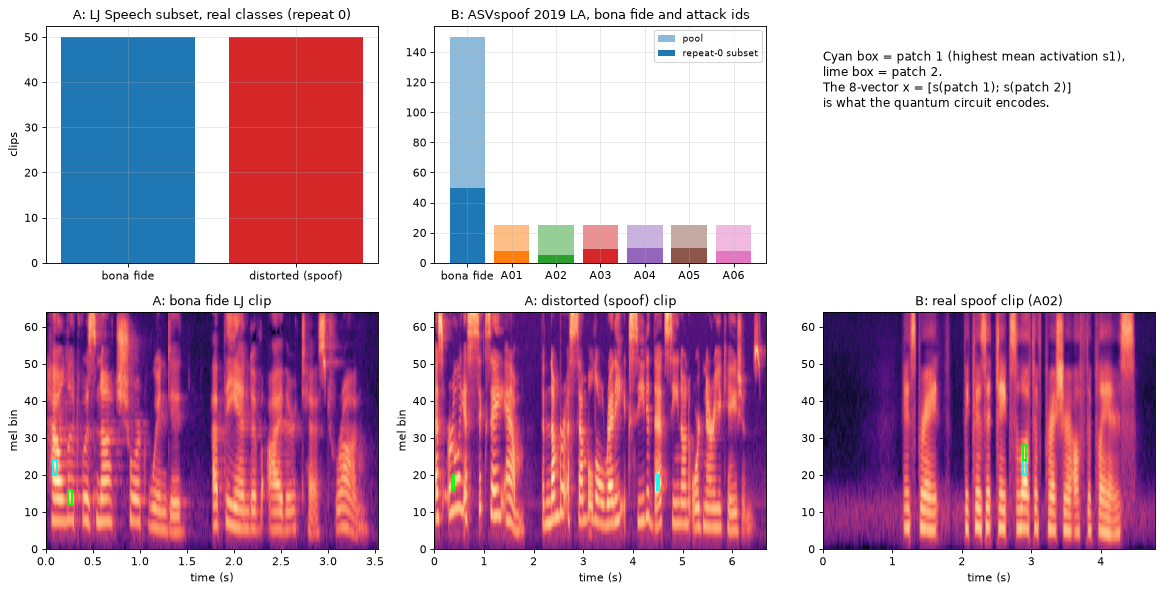

In [11]:
def patch_boxes(ax, pos):
    for k, (tb, fb) in enumerate(pos):
        ax.add_patch(plt.Rectangle((tb * 4 * HOP_MS / 1000, fb * 4), 4 * HOP_MS / 1000, 4, fill=False, ec="cyan" if k == 0 else "lime", lw=1.6))

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
# --- class distributions (bar charts of the real classes)
ax = axes[0, 0]
cnt = collections.Counter(D0.attack)
ax.bar(list(cnt), list(cnt.values()), color=["tab:blue", "tab:red"]); ax.set_title("A: LJ Speech subset, real classes (repeat 0)")
ax.set_ylabel("clips")
ax = axes[0, 1]
order = ["bona fide"] + [f"A0{k}" for k in range(1, 7)]
cnt_pool = collections.Counter(B_SYSTEM)
ax.bar(order, [cnt_pool[o] for o in order], color=["tab:blue"] + [plt.cm.tab10(k) for k in range(1, 7)], alpha=0.5, label="pool")
cnt_b = collections.Counter(DB0.attack)
ax.bar(order, [cnt_b[o] for o in order], color=["tab:blue"] + [plt.cm.tab10(k) for k in range(1, 7)], label="repeat-0 subset")
ax.set_title("B: ASVspoof 2019 LA, bona fide and attack ids"); ax.legend(fontsize=8)
# --- example spectrograms with the selected patches
ax = axes[0, 2]
ax.axis("off")
ax.text(0, 0.9, "Cyan box = patch 1 (highest mean activation s1),\nlime box = patch 2.\nThe 8-vector x = [s(patch 1); s(patch 2)]\nis what the quantum circuit encodes.", fontsize=11, va="top")
i_b = int(np.where(D0.y == 0)[0][0]); i_s = int(np.where(D0.y == 1)[0][0])
w_b, w_s = D0.wave[i_b], D0.wave[i_s]
for ax, w, pos, ttl in [(axes[1, 0], w_b, D0.pos[i_b], "A: bona fide LJ clip"), (axes[1, 1], w_s, D0.pos[i_s], "A: distorted (spoof) clip")]:
    M = log_mel_standardised(w)
    im = ax.imshow(M.T, origin="lower", aspect="auto", cmap="magma", extent=[0, len(M) * HOP_MS / 1000, 0, N_MELS])
    patch_boxes(ax, pos); ax.set_title(ttl); ax.set_xlabel("time (s)"); ax.set_ylabel("mel bin"); ax.grid(False)
ib_b = int(np.where(DB0.y == 0)[0][0]); ib_s = int(np.where(DB0.y == 1)[0][0])
ax = axes[1, 2]
Mb = log_mel_standardised(B_WAVES[DB0.src[ib_s]])
ax.imshow(Mb.T, origin="lower", aspect="auto", cmap="magma", extent=[0, len(Mb) * HOP_MS / 1000, 0, N_MELS])
patch_boxes(ax, DB0.pos[ib_s]); ax.set_title(f"B: real spoof clip ({DB0.attack[ib_s]})"); ax.set_xlabel("time (s)"); ax.grid(False)
plt.tight_layout(); plt.show()

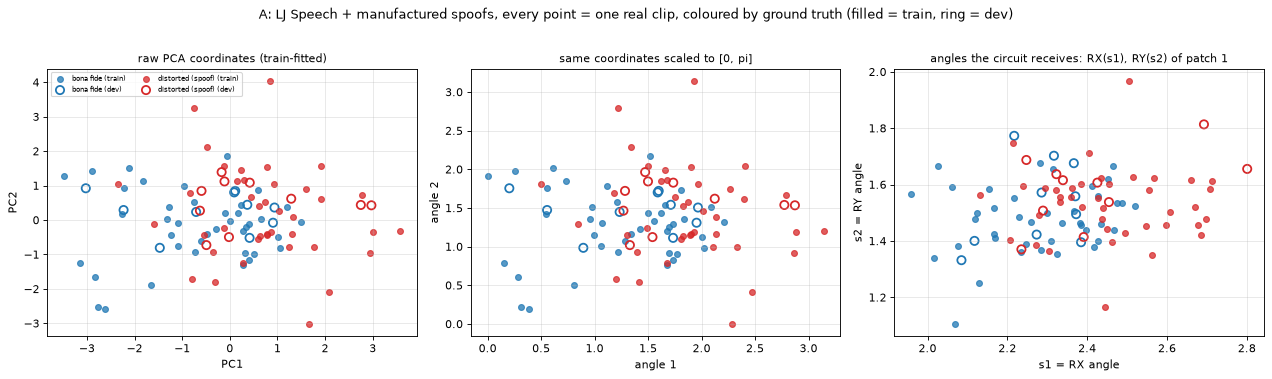

explained variance of PC1, PC2: [0.27  0.184]


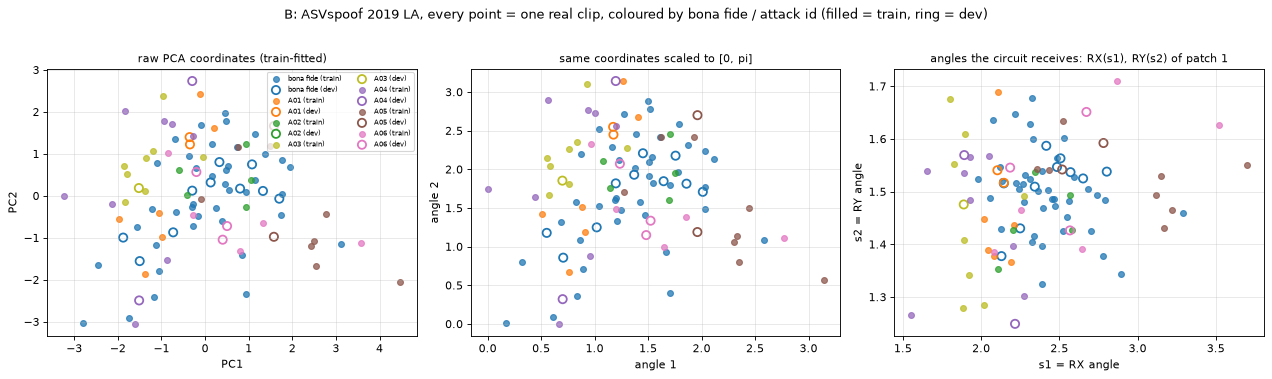

explained variance of PC1, PC2: [0.273 0.203]


In [12]:
ATTACK_COLORS = {"bona fide": "tab:blue", "distorted (spoof)": "tab:red", "A01": "tab:orange", "A02": "tab:green",
                 "A03": "tab:olive", "A04": "tab:purple", "A05": "tab:brown", "A06": "tab:pink"}

def scatter_views(D, title):
    sc = StandardScaler().fit(D.X[D.tr])
    pca = PCA(n_components=2, random_state=SEED).fit(sc.transform(D.X[D.tr]))          # fitted on the training split only
    Z = pca.transform(sc.transform(D.X))
    ang = MinMaxScaler((0, np.pi)).fit(Z[D.tr]); A = np.clip(ang.transform(Z), 0, np.pi)
    views = [(Z, "raw PCA coordinates (train-fitted)", ("PC1", "PC2")),
             (A, "same coordinates scaled to [0, pi]", ("angle 1", "angle 2")),
             (D.X[:, [0, 1]], "angles the circuit receives: RX(s1), RY(s2) of patch 1", ("s1 = RX angle", "s2 = RY angle"))]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for ax, (P, ttl, (xl, yl)) in zip(axes, views):
        for lab in sorted(set(D.attack), key=lambda s: (s != "bona fide", s)):
            m = D.attack == lab
            ax.scatter(P[m & np.isin(np.arange(len(D.y)), D.tr), 0], P[m & np.isin(np.arange(len(D.y)), D.tr), 1], s=28, alpha=0.75,
                       color=ATTACK_COLORS[lab], label=f"{lab} (train)")
            ax.scatter(P[m & np.isin(np.arange(len(D.y)), D.te), 0], P[m & np.isin(np.arange(len(D.y)), D.te), 1], s=55, facecolors="none",
                       edgecolors=ATTACK_COLORS[lab], linewidths=1.6, label=f"{lab} (dev)")
        ax.set_title(ttl, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)
    axes[0].legend(fontsize=6, ncol=2)
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()
    print("explained variance of PC1, PC2:", np.round(pca.explained_variance_ratio_, 3))

scatter_views(D0, "A: LJ Speech + manufactured spoofs, every point = one real clip, coloured by ground truth (filled = train, ring = dev)")
scatter_views(DB0, "B: ASVspoof 2019 LA, every point = one real clip, coloured by bona fide / attack id (filled = train, ring = dev)")

## Quantum Circuit Architecture

This is the circuit that is simulated for every kernel entry, built gate by gate from Eqs. (14)-(18):

* **Encoding / parametrised gates.** Per patch, four qubits receive `RX(s1)`, `RY(s2)`, `RZ(s3)`, `RY(s4)`. The 8 inputs are the angles themselves; the model has **no trainable parameters** (only the SVM dual coefficients are learned).
* **Entanglement.** `CZ(q0,q1) CZ(q1,q2) CZ(q2,q3)` inside each block and one `CZ(q3,q4)` between the two blocks. CZ gates are diagonal and therefore commute; we apply them in two layers (`CZ(0,1) CZ(2,3) CZ(4,5) CZ(6,7)` then `CZ(1,2) CZ(3,4) CZ(5,6)`), which gives exactly the "depth <= 3" claimed in the paper. The written order of Eq. (18) would be deeper; the cell below proves both orders implement the same unitary.
* **Measurement.** None: the kernel is the exact state overlap `|<phi(x)|phi(x')>|^2` from the statevector (ideal simulation, as in the paper). On hardware this would be a compute-uncompute circuit measured in the all-zero state.

Assumptions where the paper is silent: the order of the two patches, the local frequency index in `s2`/`s3`, and the use of exact statevectors instead of shots (the paper states ideal simulation). We draw three architectures: the executed 8-qubit circuit, a one-patch 4-qubit circuit (used for Table I and an ablation), and an ablation that adds a Hadamard layer first.

In [13]:
def qpatch_circuit(n_patches=2, hadamard=False, layered=True):
    """Q-Patch feature map, Eqs. (14)-(18). layered=False writes the CZ gates in the paper's literal order."""
    nq = 4 * n_patches
    th = ParameterVector("s", nq)
    qc = QuantumCircuit(nq, name=f"Q-Patch{'+H' if hadamard else ''}-{n_patches}")
    if hadamard:                                   # ablation only (not in the paper)
        qc.h(range(nq))
    for p in range(n_patches):
        b = 4 * p
        qc.rx(th[b], b); qc.ry(th[b + 1], b + 1); qc.rz(th[b + 2], b + 2); qc.ry(th[b + 3], b + 3)   # Eq. (14)
    if layered:
        for p in range(n_patches):
            qc.cz(4 * p, 4 * p + 1); qc.cz(4 * p + 2, 4 * p + 3)
        for p in range(n_patches):
            qc.cz(4 * p + 1, 4 * p + 2)
        for p in range(n_patches - 1):
            qc.cz(4 * p + 3, 4 * p + 4)                                                            # inter-patch link, Eq. (18)
    else:
        for p in range(n_patches):
            qc.cz(4 * p, 4 * p + 1); qc.cz(4 * p + 1, 4 * p + 2); qc.cz(4 * p + 2, 4 * p + 3)        # Eq. (15)
        for p in range(n_patches - 1):
            qc.cz(4 * p + 3, 4 * p + 4)
    return qc

QC8 = qpatch_circuit(2)                       # the circuit executed in all experiments
QC8_LITERAL = qpatch_circuit(2, layered=False)
QC8H = qpatch_circuit(2, hadamard=True)       # ablation
QC4 = qpatch_circuit(1)                       # one patch

th_test = np.random.default_rng(SEED).uniform(-np.pi, np.pi, 8)
same = Operator(QC8.assign_parameters(th_test)).equiv(Operator(QC8_LITERAL.assign_parameters(th_test)))
print(f"layered circuit == circuit in the paper's literal gate order (same unitary up to global phase): {same}")
assert same
rows = []
for nm, qc in [("Q-Patch, 2 patches (executed)", QC8), ("Q-Patch, literal gate order", QC8_LITERAL), ("Q-Patch + Hadamard (ablation)", QC8H), ("Q-Patch, 1 patch", QC4)]:
    rows.append({"circuit": nm, "qubits": qc.num_qubits, "depth": qc.depth(), "trainable parameters": 0,
                 "input angles": qc.num_parameters, "gates": dict(qc.count_ops())})
display(pd.DataFrame(rows))
assert QC8.depth() <= 3 and QC8.num_qubits == 8

layered circuit == circuit in the paper's literal gate order (same unitary up to global phase): True


,circuit,qubits,depth,trainable parameters,input angles,gates
0,"Q-Patch, 2 patches (executed)",8,3,0,8,"{'cz': 7, 'ry': 4, 'rx': 2, 'rz': 2}"
1,"Q-Patch, literal gate order",8,5,0,8,"{'cz': 7, 'ry': 4, 'rx': 2, 'rz': 2}"
2,Q-Patch + Hadamard (ablation),8,4,0,8,"{'h': 8, 'cz': 7, 'ry': 4, 'rx': 2, 'rz': 2}"
3,"Q-Patch, 1 patch",4,3,0,4,"{'cz': 3, 'ry': 2, 'rx': 1, 'rz': 1}"


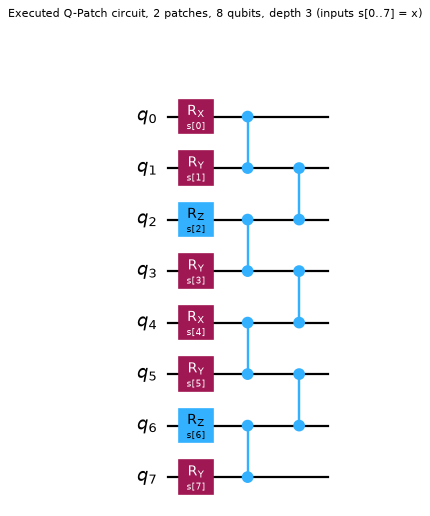

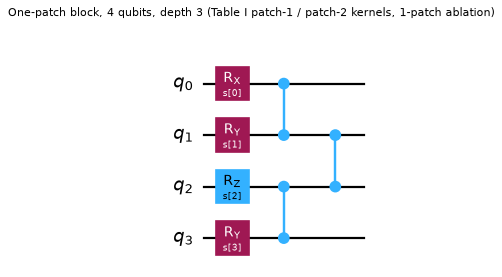

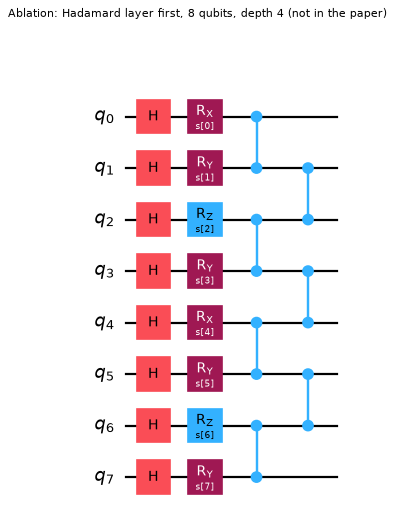

In [14]:
for qc, ttl in [(QC8, "Executed Q-Patch circuit, 2 patches, 8 qubits, depth %d (inputs s[0..7] = x)" % QC8.depth()),
                (QC4, "One-patch block, 4 qubits, depth %d (Table I patch-1 / patch-2 kernels, 1-patch ablation)" % QC4.depth()),
                (QC8H, "Ablation: Hadamard layer first, 8 qubits, depth %d (not in the paper)" % QC8H.depth())]:
    fig = qc.draw("mpl", fold=-1, style="iqp")
    fig.suptitle(ttl, y=1.0, fontsize=10)
    display(fig); plt.close(fig)

In [15]:
def q_states(qc, X):
    """One exact statevector per row of X (the rows are the circuit's rotation angles in radians)."""
    return np.array([Statevector(qc.assign_parameters(list(map(float, x)))).data for x in X])

def q_gram(Sa, Sb):
    return np.abs(Sa.conj() @ Sb.T) ** 2                 # |<phi(x)|phi(x')>|^2, Eq. (19)

# (1) our hand-made Gram matrix versus Qiskit's own fidelity kernel on the real repeat-0 features
S0 = q_states(QC8, D0.X)
K0 = q_gram(S0, S0)
K_qiskit = FidelityStatevectorKernel(feature_map=QC8).evaluate(D0.X, D0.X)
print("hand-made Gram == FidelityStatevectorKernel:", np.allclose(K0, K_qiskit, atol=1e-8),
      "| unit diagonal:", np.allclose(np.diag(K0), 1.0), "| smallest eigenvalue (PSD check): %.2e" % np.linalg.eigvalsh(K0).min())

# (2) which inputs and gates actually act? RZ on |0> is a global phase, and a CZ whose partner qubit is still |0> does nothing.
def eff_kernel(X):
    """Kernel from three small independent sub-circuits: {q0,q1}, {q3,q4,q5}, {q7}."""
    c01 = QuantumCircuit(2); t = ParameterVector("a", 2); c01.rx(t[0], 0); c01.ry(t[1], 1); c01.cz(0, 1)
    c345 = QuantumCircuit(3); u = ParameterVector("b", 3); c345.ry(u[0], 0); c345.rx(u[1], 1); c345.ry(u[2], 2); c345.cz(0, 1); c345.cz(1, 2)
    c7 = QuantumCircuit(1); v = ParameterVector("c", 1); c7.ry(v[0], 0)
    K = np.ones((len(X), len(X)))
    for qc, cols in [(c01, [0, 1]), (c345, [3, 4, 5]), (c7, [7])]:
        S = q_states(qc, X[:, cols]); K *= q_gram(S, S)
    return K
K_eff = eff_kernel(D0.X)
print("full 8-qubit kernel == product of three small kernels using only s1,s2,s4 of patch 1 and s1',s2',s4' of patch 2:",
      np.allclose(K0, K_eff, atol=1e-8), "(max abs diff %.1e)" % np.abs(K0 - K_eff).max())
Xp = D0.X.copy(); rng_ = np.random.default_rng(SEED)
for c in (2, 6):                                       # destroy the bandwidth features s3 completely
    Xp[:, c] = rng_.permutation(Xp[:, c]) + 3.0
Kp = q_gram(q_states(QC8, Xp), q_states(QC8, Xp))
print("kernel unchanged after shuffling and shifting both bandwidth inputs s3 (columns 2 and 6):", np.allclose(K0, Kp, atol=1e-8))
Kh = q_gram(q_states(QC8H, Xp), q_states(QC8H, Xp)); Kh0 = q_gram(q_states(QC8H, D0.X), q_states(QC8H, D0.X))
print("with a Hadamard layer in front (ablation) the same shuffle DOES change the kernel (max abs change %.3f)" % np.abs(Kh - Kh0).max())

hand-made Gram == FidelityStatevectorKernel: True | unit diagonal: True | smallest eigenvalue (PSD check): 5.65e-14


full 8-qubit kernel == product of three small kernels using only s1,s2,s4 of patch 1 and s1',s2',s4' of patch 2: True (max abs diff 1.6e-15)


kernel unchanged after shuffling and shifting both bandwidth inputs s3 (columns 2 and 6): True


with a Hadamard layer in front (ablation) the same shuffle DOES change the kernel (max abs change 0.013)


## 4. Models: Q-Patch QSVM, the paper's baselines, and extra references

Everything below is fitted on the **80 training clips only**; the 20 dev clips are used once for scoring.

* **Q-Patch QSVM**: Gram matrix from the circuit above, `SVC(kernel="precomputed")`; `C` chosen by 5-fold inner CV (AUROC) on the training clips.
* **RBF-SVM** (the paper's direct control): the same 8 numbers, `StandardScaler` fitted on the training clips, `C` and `gamma` by the same inner CV. The raw-input and the default (`C=1`, `gamma="scale"`) variants are listed too.
* **Tiny CNN** (the paper's second baseline): 97,761 parameters on the 64 x 200 standardised spectrogram.
* **Extras not in the paper**: a Random Forest on the same 8 numbers; a logistic regression on 128 per-band statistics of the *whole* spectrogram (a reference for how easy the manufactured-spoof task is without any patch selection); a logistic regression on the clip duration only (a leakage check); three quantum ablations (a Hadamard layer in front, a single patch with 4 qubits, and the same circuit fed with z-scored instead of raw angles).

Metrics follow the paper: AUROC and EER (the point where false-positive rate equals false-negative rate; spoof = positive class), computed from continuous decision scores.

In [16]:
def tune_C_precomputed(Ktr, ytr):
    skf = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED)
    best = (-1.0, None)
    for C in C_GRID:
        aucs = []
        for a, b in skf.split(Ktr, ytr):
            m = SVC(kernel="precomputed", C=C).fit(Ktr[np.ix_(a, a)], ytr[a])
            aucs.append(roc_auc_score(ytr[b], m.decision_function(Ktr[np.ix_(b, a)])))
        if np.mean(aucs) > best[0] + 1e-9:
            best = (float(np.mean(aucs)), C)
    return best[1]

class TinyCNN(nn.Module):
    """CHOICE: 4 conv blocks 16-32-64-128, BatchNorm, max-pool, global average pool, linear. 97,761 parameters (<= 100k)."""
    def __init__(self):
        super().__init__()
        ch, L = [1, 16, 32, 64, 128], []
        for a, b in zip(ch[:-1], ch[1:]):
            L += [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(), nn.MaxPool2d(2)]
        self.f = nn.Sequential(*L, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 1))
    def forward(self, x):
        return self.f(x).squeeze(1)

N_CNN_PARAMS = sum(p.numel() for p in TinyCNN().parameters())
print("tiny CNN trainable parameters:", f"{N_CNN_PARAMS:,}", "(paper: 98.4K, limit 100k)")

def train_cnn(Str, ytr, Ste, seed):
    torch.manual_seed(seed)
    m = TinyCNN(); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-3)
    Xt = torch.from_numpy(Str.astype(np.float32))[:, None]; yt = torch.from_numpy(ytr.astype(np.float32))
    g = torch.Generator().manual_seed(seed)
    for ep in range(CNN_EPOCHS):
        m.train(); perm = torch.randperm(len(Xt), generator=g)
        for i in range(0, len(Xt), 16):
            b = perm[i:i + 16]
            if len(b) < 2:
                continue
            opt.zero_grad(); loss = nn.functional.binary_cross_entropy_with_logits(m(Xt[b]), yt[b]); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        return m(torch.from_numpy(Ste.astype(np.float32))[:, None]).numpy()

QZ = "Q-Patch + z-scored angles (ablation)"
QMODELS = {"Q-Patch (paper circuit)": (QC8, slice(0, 8)),
           "Q-Patch + Hadamard (ablation)": (QC8H, slice(0, 8)),
           "Q-Patch 1 patch (4 qubits)": (QC4, slice(0, 4)),
           QZ: (QC8, slice(0, 8))}
PAPER_MODELS = ["Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)", "Tiny CNN"]
ALL_MODELS = list(QMODELS) + ["RBF-SVM (standardised, tuned)", "RBF-SVM (raw x, tuned)", "RBF-SVM (default)", "RandomForest",
                              "LogReg, 128 band statistics (reference)", "LogReg, duration only (leakage check)", "Tiny CNN"]

def eval_all(D, r, which=None, cnn=False):
    """Fit every model on D.tr, score D.te. Returns {model: dict(scores, auroc, eer, acc, secs, extra)}."""
    X, y, tr, te = D.X, D.y, D.tr, D.te
    out = {}
    def rec(name, s, t0, **extra):
        a, e = auroc_eer(y[te], s)
        out[name] = dict(scores=np.asarray(s), auroc=a, eer=e, acc=float(np.mean((np.asarray(s) > 0) == y[te])), secs=time.time() - t0, **extra)
    want = lambda n: which is None or n in which
    for name, (qc, cols) in QMODELS.items():
        if want(name):
            t0 = time.time()
            Xq = X[:, cols]
            if name == QZ:                                    # ablation: angles = z-scores fitted on the training clips
                Xq = StandardScaler().fit(X[tr]).transform(X)
            S = q_states(qc, Xq); K = q_gram(S, S)
            C = tune_C_precomputed(K[np.ix_(tr, tr)], y[tr])
            m = SVC(kernel="precomputed", C=C).fit(K[np.ix_(tr, tr)], y[tr])
            rec(name, m.decision_function(K[np.ix_(te, tr)]), t0, C=C, K=K if r == 0 else None, nsv=len(m.support_))
    if want("RBF-SVM (standardised, tuned)"):
        t0 = time.time(); gs = tuned_rbf(X[tr], y[tr], True)
        rec("RBF-SVM (standardised, tuned)", gs.decision_function(X[te]), t0, params=gs.best_params_)
    if want("RBF-SVM (raw x, tuned)"):
        t0 = time.time(); gs = tuned_rbf(X[tr], y[tr], False)
        rec("RBF-SVM (raw x, tuned)", gs.decision_function(X[te]), t0, params=gs.best_params_)
    if want("RBF-SVM (default)"):
        t0 = time.time(); m = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")).fit(X[tr], y[tr])
        rec("RBF-SVM (default)", m.decision_function(X[te]), t0)
    if want("RandomForest"):
        t0 = time.time(); m = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(X[tr], y[tr])
        rec("RandomForest", m.predict_proba(X[te])[:, 1] - 0.5, t0)
    if want("LogReg, 128 band statistics (reference)"):
        t0 = time.time(); m = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)).fit(D.band[tr], y[tr])
        rec("LogReg, 128 band statistics (reference)", m.decision_function(D.band[te]), t0)
    if want("LogReg, duration only (leakage check)"):
        t0 = time.time(); F = np.log(D.dur)[:, None]
        m = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED)).fit(F[tr], y[tr])
        rec("LogReg, duration only (leakage check)", m.decision_function(F[te]), t0)
    if cnn and want("Tiny CNN"):
        t0 = time.time(); rec("Tiny CNN", train_cnn(D.spec[tr], y[tr], D.spec[te], SEED + r), t0)
    return out

t0 = time.time()
OUT0 = eval_all(D0, 0, cnn=True)
print(f"repeat 0 (paper-style single split) done in {time.time() - t0:.0f}s")
tab0 = pd.DataFrame({m: dict(AUROC=o["auroc"], EER=o["eer"], acc=o["acc"], seconds=o["secs"]) for m, o in OUT0.items()}).T
display(tab0.round(3))

tiny CNN trainable parameters: 97,761 (paper: 98.4K, limit 100k)


repeat 0 (paper-style single split) done in 105s


,AUROC,EER,acc,seconds
Q-Patch (paper circuit),0.610,0.55,0.50,0.633
Q-Patch + Hadamard (ablation),0.560,0.45,0.55,0.765
Q-Patch 1 patch (4 qubits),0.670,0.35,0.60,0.461
Q-Patch + z-scored angles (ablation),0.540,0.50,0.55,0.600
"RBF-SVM (standardised, tuned)",0.610,0.55,0.45,2.270
"RBF-SVM (raw x, tuned)",0.610,0.55,0.50,1.355
RBF-SVM (default),0.740,0.40,0.60,0.010
RandomForest,0.775,0.40,0.65,0.711
"LogReg, 128 band statistics (reference)",1.000,0.00,0.85,0.033
"LogReg, duration only (leakage check)",0.440,0.55,0.40,0.014


## 5. The kernel picture (Fig. 4) and the similarity table (Table I)

Fig. 4 of the paper shows the dev-set Gram matrix ordered by class. Table I lists average fidelities: self-similarity (always 1), bona fide-bona fide and spoof-spoof across *different* clips, and bona fide-spoof. The "(patch 1)" and "(patch 2)" rows are ambiguous in the paper; we read them as the cross-class fidelity of a 4-qubit circuit that encodes only that patch. To get stable numbers we pool the per-clip mean similarities of the dev sets of all repeats (Part A) and also show repeat 0 alone.

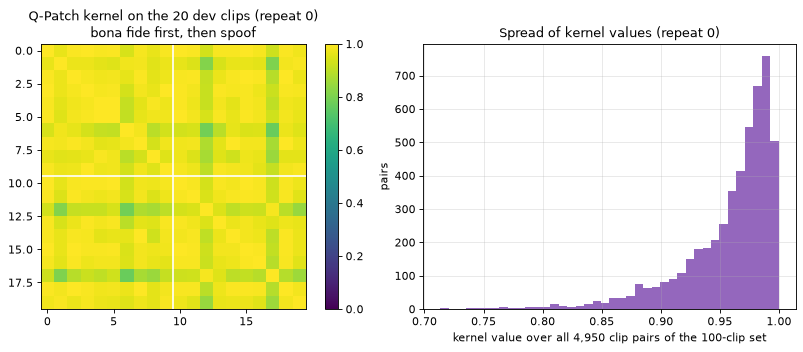

In [17]:
def sim_means(K, y):
    """Per-clip mean similarity to the clips of the same class (excluding itself) and to the other class."""
    same, cross = {0: [], 1: []}, {0: [], 1: []}
    for i in range(len(y)):
        o = np.arange(len(y)) != i
        same[y[i]].append(K[i, o & (y == y[i])].mean()); cross[y[i]].append(K[i, y != y[i]].mean())
    return same, cross

def table1_stats(D):
    te, y = D.te, D.y[D.te]
    S = q_states(QC8, D.X[te]); K = q_gram(S, S)
    S1 = q_states(QC4, D.X[te][:, :4]); S2 = q_states(QC4, D.X[te][:, 4:])
    K1, K2 = q_gram(S1, S1), q_gram(S2, S2)
    same, cross = sim_means(K, y)
    _, cross1 = sim_means(K1, y); _, cross2 = sim_means(K2, y)
    Xz = StandardScaler().fit(D.X[D.tr]).transform(D.X)[te]              # ablation: z-scored angles (train-fitted)
    Sz = q_states(QC8, Xz); Kz = q_gram(Sz, Sz); samez, crossz = sim_means(Kz, y)
    return {"self (diagonal)": [float(np.diag(K).mean())],
            "[z-scored angles] bona fide - bona fide": samez[0], "[z-scored angles] spoof - spoof": samez[1],
            "[z-scored angles] bona fide - spoof": crossz[0] + crossz[1],
            "bona fide - bona fide (different clips)": same[0], "spoof - spoof (different clips)": same[1],
            "bona fide - spoof (8-qubit kernel)": cross[0] + cross[1],
            "bona fide - spoof (patch 1 only)": cross1[0] + cross1[1], "bona fide - spoof (patch 2 only)": cross2[0] + cross2[1]}, K

T1_0, K_dev0 = table1_stats(D0)
T1_ALL = collections.defaultdict(list)
for k, v in T1_0.items():
    T1_ALL[k] += v

# --- Fig. 4 analogue (repeat 0, dev set ordered by class)
order = np.argsort(D0.y[D0.te], kind="stable")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im = axes[0].imshow(K_dev0[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1); axes[0].grid(False)
nb = int((D0.y[D0.te] == 0).sum()); axes[0].axhline(nb - 0.5, color="w"); axes[0].axvline(nb - 0.5, color="w")
axes[0].set_title("Q-Patch kernel on the 20 dev clips (repeat 0)\nbona fide first, then spoof"); plt.colorbar(im, ax=axes[0], fraction=0.046)
Ktr_full = OUT0["Q-Patch (paper circuit)"]["K"]
axes[1].hist(Ktr_full[np.triu_indices(100, 1)], bins=40, color="tab:purple"); axes[1].set_xlabel("kernel value over all 4,950 clip pairs of the 100-clip set")
axes[1].set_title("Spread of kernel values (repeat 0)"); axes[1].set_ylabel("pairs")
plt.tight_layout(); plt.show()

## 6. Table II over many splits

The paper evaluates on one split of 20 clips, where a single clip changes AUROC by about 0.02 and EER by 0.1. We therefore repeat the whole protocol `N_REPEATS` times: every repeat draws a **new** random set of 100 utterances, picks which 50 are distorted, generates **new** random spoof parameters, makes a new stratified 80/20 split and refits every model (including the choice of `C`/`gamma`). Repeat 0 is the paper-style single split reported above. The Tiny CNN, the slow model, is trained on the first `N_CNN_REPEATS` repeats only.

In [18]:
RES = []
def add_results(tag, r, out):
    for m, o in out.items():
        RES.append(dict(part=tag, repeat=r, model=m, auroc=o["auroc"], eer=o["eer"], acc=o["acc"], secs=o["secs"]))
add_results("A", 0, OUT0)
SC0 = {m: (D0.y[D0.te], o["scores"]) for m, o in OUT0.items()}          # repeat-0 scores for the ROC plot

t0 = time.time()
for r in range(1, N_REPEATS):
    D = build_A(r, spectra=(r < N_CNN_REPEATS))
    out = eval_all(D, r, cnn=(r < N_CNN_REPEATS))
    add_results("A", r, out)
    for k, v in table1_stats(D)[0].items():
        T1_ALL[k] += v
    if r % max(1, N_REPEATS // 5) == 0:
        print(f"  repeat {r:3d}/{N_REPEATS}  elapsed {time.time() - t0:5.0f}s  Q-Patch AUROC {out['Q-Patch (paper circuit)']['auroc']:.2f}  "
              f"RBF-SVM {out['RBF-SVM (standardised, tuned)']['auroc']:.2f}", flush=True)
R = pd.DataFrame(RES)
RA = R[R.part == "A"]
print(f"{N_REPEATS} repeats done in {time.time() - t0:.0f}s ({len(RA)} model fits scored)")

  repeat  10/50  elapsed   873s  Q-Patch AUROC 0.84  RBF-SVM 0.82


  repeat  20/50  elapsed  1025s  Q-Patch AUROC 0.74  RBF-SVM 0.66


  repeat  30/50  elapsed  1133s  Q-Patch AUROC 0.81  RBF-SVM 0.88


  repeat  40/50  elapsed  1223s  Q-Patch AUROC 0.77  RBF-SVM 0.75


50 repeats done in 1333s (508 model fits scored)


,n repeats,AUROC repeat 0,AUROC mean,AUROC std,EER repeat 0 (%),EER mean (%),EER std (%),paper AUROC,paper EER (%)
Model,,,,,,,,,
Q-Patch (paper circuit),50,0.610,0.779,0.114,55.0,28.6,12.9,0.87,14.8
Q-Patch + Hadamard (ablation),50,0.560,0.491,0.138,45.0,48.4,13.8,NaN,NaN
Q-Patch 1 patch (4 qubits),50,0.670,0.771,0.114,35.0,28.5,12.2,NaN,NaN
Q-Patch + z-scored angles (ablation),50,0.540,0.727,0.130,50.0,30.2,11.5,NaN,NaN
"RBF-SVM (standardised, tuned)",50,0.610,0.767,0.123,55.0,27.5,13.5,0.82,18.2
"RBF-SVM (raw x, tuned)",50,0.610,0.778,0.117,55.0,28.1,13.0,NaN,NaN
RBF-SVM (default),50,0.740,0.742,0.128,40.0,29.9,14.1,NaN,NaN
RandomForest,50,0.775,0.744,0.126,40.0,30.1,12.0,NaN,NaN
"LogReg, 128 band statistics (reference)",50,1.000,0.996,0.012,0.0,2.0,5.4,NaN,NaN


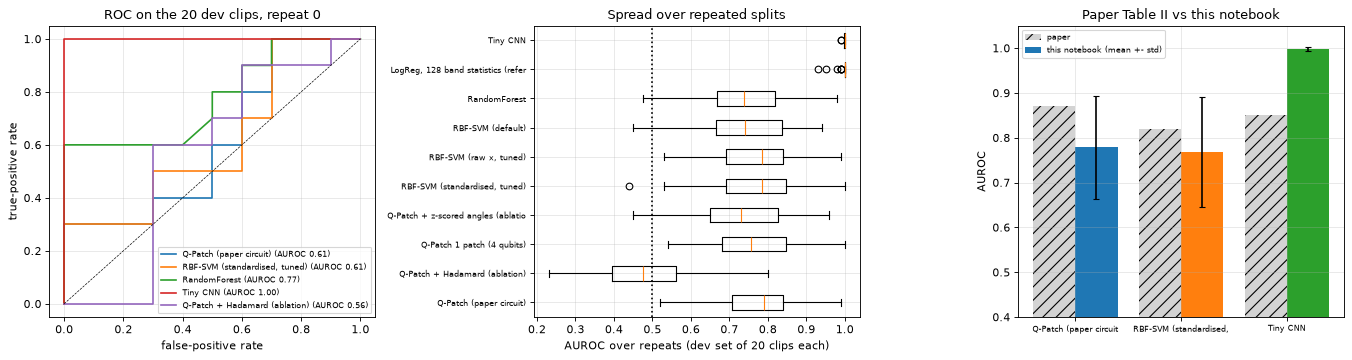

AUROC Q-Patch (paper circuit)  minus  RBF-SVM (standardised, tuned): n=50, mean diff +0.011, 95% bootstrap CI [-0.004, +0.028], Q higher in 58% of repeats, Wilcoxon p=0.227
AUROC Q-Patch (paper circuit)  minus  RBF-SVM (raw x, tuned): n=50, mean diff +0.000, 95% bootstrap CI [-0.005, +0.006], Q higher in 28% of repeats, Wilcoxon p=0.828


AUROC Q-Patch (paper circuit)  minus  RandomForest: n=50, mean diff +0.035, 95% bootstrap CI [+0.013, +0.056], Q higher in 72% of repeats, Wilcoxon p=0.001
AUROC Q-Patch (paper circuit)  minus  Tiny CNN: n=8, mean diff -0.245, 95% bootstrap CI [-0.355, -0.131], Q higher in 0% of repeats, Wilcoxon p=0.008


AUROC Q-Patch + Hadamard (ablation)  minus  Q-Patch (paper circuit): n=50, mean diff -0.288, 95% bootstrap CI [-0.340, -0.233], Q higher in 6% of repeats, Wilcoxon p=0.000


In [19]:
PAPER_T2 = {"RBF-SVM (standardised, tuned)": dict(auroc=0.82, eer=0.182), "Tiny CNN": dict(auroc=0.85, eer=0.163),
            "Q-Patch (paper circuit)": dict(auroc=0.87, eer=0.148)}
def summarise(R_, models):
    rows = []
    for m in models:
        g = R_[R_.model == m]
        if len(g) == 0:
            continue
        g0 = g[g.repeat == 0].iloc[0]
        rows.append({"Model": m, "n repeats": len(g), "AUROC repeat 0": round(g0.auroc, 3), "AUROC mean": round(g.auroc.mean(), 3),
                     "AUROC std": round(g.auroc.std(ddof=1), 3) if len(g) > 1 else np.nan, "EER repeat 0 (%)": round(100 * g0.eer, 1),
                     "EER mean (%)": round(100 * g.eer.mean(), 1), "EER std (%)": round(100 * g.eer.std(ddof=1), 1) if len(g) > 1 else np.nan,
                     "paper AUROC": PAPER_T2.get(m, {}).get("auroc", np.nan), "paper EER (%)": 100 * PAPER_T2[m]["eer"] if m in PAPER_T2 else np.nan})
    return pd.DataFrame(rows).set_index("Model")
T2 = summarise(RA, ALL_MODELS)
display(T2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
colors = plt.cm.tab10(np.arange(10))
for k, m in enumerate(["Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)", "RandomForest", "Tiny CNN", "Q-Patch + Hadamard (ablation)"]):
    y_, s_ = SC0[m]; fpr, tpr, _ = roc_curve(y_, s_)
    axes[0].plot(fpr, tpr, color=colors[k], label=f"{m} (AUROC {roc_auc_score(y_, s_):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.6); axes[0].set_title("ROC on the 20 dev clips, repeat 0"); axes[0].set_xlabel("false-positive rate"); axes[0].set_ylabel("true-positive rate"); axes[0].legend(fontsize=7)
mods = [m for m in ALL_MODELS if m in set(RA.model) and "duration" not in m]
axes[1].boxplot([RA[RA.model == m].auroc.values for m in mods], vert=False); axes[1].set_yticklabels([m[:34] for m in mods], fontsize=7); axes[1].axvline(0.5, color="k", ls=":")
axes[1].set_xlabel("AUROC over repeats (dev set of 20 clips each)"); axes[1].set_title("Spread over repeated splits")
for k, m in enumerate(PAPER_MODELS):
    g = RA[RA.model == m]
    axes[2].bar(k - 0.2, PAPER_T2[m]["auroc"], 0.4, color="lightgray", hatch="//", label="paper" if k == 0 else None)
    axes[2].bar(k + 0.2, g.auroc.mean(), 0.4, yerr=g.auroc.std(ddof=1), capsize=3, color=colors[k], label="this notebook (mean +- std)" if k == 0 else None)
axes[2].set_xticks(range(3)); axes[2].set_xticklabels([m[:22] for m in PAPER_MODELS], fontsize=7); axes[2].set_ylim(0.4, 1.05); axes[2].set_ylabel("AUROC"); axes[2].legend(fontsize=7)
axes[2].set_title("Paper Table II vs this notebook")
plt.tight_layout(); plt.show()

# paired comparison Q-Patch vs the paper's direct control
def paired(R_, a, b, key="auroc"):
    pa = R_[R_.model == a].set_index("repeat")[key]; pb = R_[R_.model == b].set_index("repeat")[key]
    idx = pa.index.intersection(pb.index); d = (pa.loc[idx] - pb.loc[idx]).values
    rng = np.random.default_rng(SEED); boots = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    try:
        p = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    except ValueError:
        p = np.nan
    return dict(n=len(d), mean_diff=d.mean(), ci95=(np.percentile(boots, 2.5), np.percentile(boots, 97.5)), wins=float((d > 0).mean()), ties=float((d == 0).mean()), p_wilcoxon=p)
PAIR = {}
for a, b in [("Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)"), ("Q-Patch (paper circuit)", "RBF-SVM (raw x, tuned)"), ("Q-Patch (paper circuit)", "RandomForest"),
             ("Q-Patch (paper circuit)", "Tiny CNN"), ("Q-Patch + Hadamard (ablation)", "Q-Patch (paper circuit)")]:
    PAIR[(a, b)] = paired(RA, a, b)
    p = PAIR[(a, b)]
    print(f"AUROC {a}  minus  {b}: n={p['n']}, mean diff {p['mean_diff']:+.3f}, 95% bootstrap CI [{p['ci95'][0]:+.3f}, {p['ci95'][1]:+.3f}], "
          f"Q higher in {100 * p['wins']:.0f}% of repeats, Wilcoxon p={p['p_wilcoxon']:.3f}")

In [20]:
PAPER_T1 = {"self (diagonal)": 1.000, "bona fide - bona fide (different clips)": 0.675, "spoof - spoof (different clips)": 0.622,
            "bona fide - spoof (patch 1 only)": 0.614, "bona fide - spoof (patch 2 only)": 0.616}
PAPER_ZREF = {"[z-scored angles] bona fide - bona fide": 0.675, "[z-scored angles] spoof - spoof": 0.622, "[z-scored angles] bona fide - spoof": 0.615}
rows = []
for k in ["self (diagonal)", "bona fide - bona fide (different clips)", "spoof - spoof (different clips)",
          "bona fide - spoof (patch 1 only)", "bona fide - spoof (patch 2 only)", "bona fide - spoof (8-qubit kernel)",
          "[z-scored angles] bona fide - bona fide", "[z-scored angles] spoof - spoof", "[z-scored angles] bona fide - spoof"]:
    v = np.array(T1_ALL[k]); v0 = np.array(T1_0[k])
    rows.append({"Comparison": k, "paper": PAPER_T1.get(k, PAPER_ZREF.get(k, np.nan)), "repeat 0": f"{v0.mean():.3f} +- {v0.std():.3f}",
                 f"all {N_REPEATS} repeats": f"{v.mean():.3f} +- {v.std():.3f}", "_mean": v.mean()})
T1 = pd.DataFrame(rows).set_index("Comparison")
display(T1.drop(columns="_mean"))
print("(+- = std of per-clip mean similarities. The paper's Table I also lists 'delta from ideal' = similarity - 1.)")
print("Rows marked [z-scored angles] are an ablation: the same circuit, but the 8 numbers are first z-scored with training-clip statistics, which spreads the angles out.")

,paper,repeat 0,all 50 repeats
Comparison,,,
self (diagonal),1.000,1.000 +- 0.000,1.000 +- 0.000
bona fide - bona fide (different clips),0.675,0.969 +- 0.012,0.966 +- 0.017
spoof - spoof (different clips),0.622,0.956 +- 0.021,0.959 +- 0.022
bona fide - spoof (patch 1 only),0.614,0.976 +- 0.019,0.973 +- 0.019
bona fide - spoof (patch 2 only),0.616,0.980 +- 0.013,0.975 +- 0.017
bona fide - spoof (8-qubit kernel),NaN,0.957 +- 0.031,0.949 +- 0.033
[z-scored angles] bona fide - bona fide,0.675,0.168 +- 0.064,0.188 +- 0.107
[z-scored angles] spoof - spoof,0.622,0.207 +- 0.126,0.162 +- 0.103
[z-scored angles] bona fide - spoof,0.615,0.194 +- 0.115,0.146 +- 0.107


(+- = std of per-clip mean similarities. The paper's Table I also lists 'delta from ideal' = similarity - 1.)
Rows marked [z-scored angles] are an ablation: the same circuit, but the 8 numbers are first z-scored with training-clip statistics, which spreads the angles out.


## 7. Extension: how much does the answer depend on the spoof recipe? (severity sweep)

The paper does not give its distortion parameters, and the quantum-versus-classical gap on 8 summary numbers could depend on how strong they are. We rerun the protocol for the calibrated (**default**) severity, a **mild** one (noise 15 dB weaker) and a **strong** one (noise 15 dB stronger), with `SWEEP_REPEATS` repeats each, for Q-Patch, the standardised RBF-SVM, Random Forest and the whole-spectrogram reference. This is not in the paper.

model,Q-Patch (paper circuit),"RBF-SVM (standardised, tuned)",RandomForest,"LogReg, 128 band statistics (reference)",n repeats
level,,,,,
default (calibrated),0.752,0.723,0.727,0.992,10
mild (calibrated SNR + 15 dB),0.539,0.507,0.557,0.725,10
strong (calibrated SNR - 15 dB),0.984,0.989,0.980,1.000,10


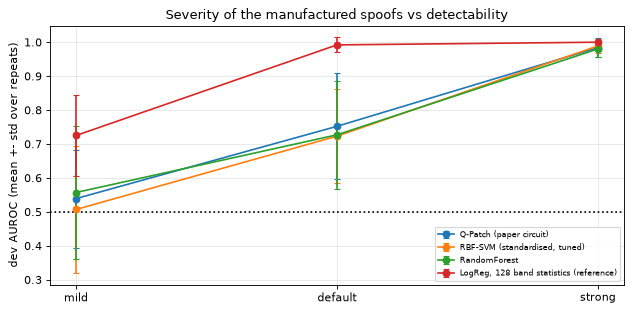

sweep done in 320s


In [21]:
SWEEP = [("mild    (calibrated SNR + 15 dB)", (SPOOF_SNR_RANGE[0] + 15.0, SPOOF_SNR_RANGE[1] + 15.0), SPOOF_EQ_DB),
         ("default (calibrated)", SPOOF_SNR_RANGE, SPOOF_EQ_DB),
         ("strong  (calibrated SNR - 15 dB)", (SPOOF_SNR_RANGE[0] - 15.0, SPOOF_SNR_RANGE[1] - 15.0), SPOOF_EQ_DB)]
SW_MODELS = ["Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)", "RandomForest", "LogReg, 128 band statistics (reference)"]
rows = []
t0 = time.time()
for name, snr, eq in SWEEP:
    for r in range(SWEEP_REPEATS):
        out = eval_all(build_A(r, snr_range=snr, eq_db=eq), r, which=SW_MODELS)
        for m, o in out.items():
            rows.append(dict(level=name, repeat=r, model=m, auroc=o["auroc"], eer=o["eer"]))
SW = pd.DataFrame(rows)
tab = SW.groupby(["level", "model"]).auroc.agg(["mean", "std"]).round(3).unstack("model")
display(tab["mean"][SW_MODELS].assign(**{"n repeats": SWEEP_REPEATS}))
fig, ax = plt.subplots(figsize=(8, 4))
for k, m in enumerate(SW_MODELS):
    g = SW[SW.model == m].groupby("level").auroc.agg(["mean", "std"]).loc[[s[0] for s in SWEEP]]
    ax.errorbar(range(3), g["mean"], g["std"], marker="o", capsize=3, label=m, color=colors[k])
ax.set_xticks(range(3)); ax.set_xticklabels(["mild", "default", "strong"]); ax.axhline(0.5, color="k", ls=":"); ax.set_ylabel("dev AUROC (mean +- std over repeats)")
ax.set_title("Severity of the manufactured spoofs vs detectability"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"sweep done in {time.time() - t0:.0f}s")

## 8. Extension: the same pipeline on real spoofs (ASVspoof 2019 LA)

Same protocol, same models (except the CNN), but the 50 + 50 clips come from the ASVspoof 2019 LA training partition: 50 genuine recordings and 50 clips produced by the TTS / voice-conversion systems A01-A06. Everything is re-drawn at each repeat. The extra "duration only" row checks whether clip length alone separates the classes (a well-known artefact of this corpus).

,n repeats,AUROC repeat 0,AUROC mean,AUROC std,EER repeat 0 (%),EER mean (%),EER std (%)
Model,,,,,,,
Q-Patch (paper circuit),30,0.680,0.687,0.122,40.0,38.7,11.1
Q-Patch + Hadamard (ablation),30,0.530,0.523,0.143,50.0,47.8,12.4
Q-Patch 1 patch (4 qubits),30,0.730,0.690,0.112,30.0,37.0,11.5
Q-Patch + z-scored angles (ablation),30,0.630,0.701,0.102,45.0,34.8,10.5
"RBF-SVM (standardised, tuned)",30,0.770,0.719,0.124,30.0,33.5,12.4
"RBF-SVM (raw x, tuned)",30,0.690,0.675,0.104,40.0,37.7,11.0
RBF-SVM (default),30,0.750,0.735,0.112,35.0,31.7,12.2
RandomForest,30,0.725,0.757,0.112,25.0,32.5,11.7
"LogReg, 128 band statistics (reference)",30,1.000,0.996,0.008,0.0,2.5,4.5


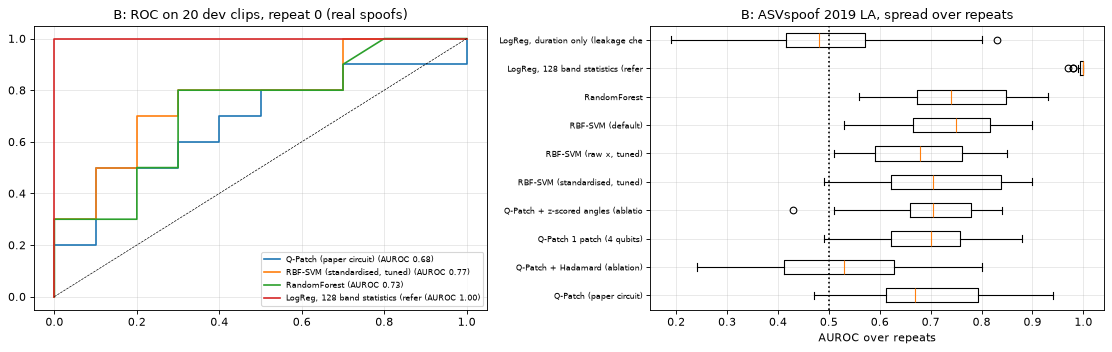

B: AUROC Q-Patch minus RBF-SVM: mean diff -0.032, 95% CI [-0.081, +0.018], Q-Patch higher in 30% of 30 repeats, Wilcoxon p=0.088  (264s)


In [22]:
t0 = time.time()
B_MODELS = [m for m in ALL_MODELS if m != "Tiny CNN"]
RESB = []
for r in range(N_REPEATS_B):
    D = DB0 if r == 0 else build_B(r)
    out = eval_all(D, r, which=B_MODELS)
    for m, o in out.items():
        RESB.append(dict(part="B", repeat=r, model=m, auroc=o["auroc"], eer=o["eer"], acc=o["acc"], secs=o["secs"]))
    if r == 0:
        SCB0 = {m: (D.y[D.te], o["scores"]) for m, o in out.items()}
RB = pd.DataFrame(RESB)
T2B = summarise(RB, B_MODELS).drop(columns=["paper AUROC", "paper EER (%)"])
display(T2B)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for k, m in enumerate(["Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)", "RandomForest", "LogReg, 128 band statistics (reference)"]):
    y_, s_ = SCB0[m]; fpr, tpr, _ = roc_curve(y_, s_)
    axes[0].plot(fpr, tpr, color=colors[k], label=f"{m[:34]} (AUROC {roc_auc_score(y_, s_):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.6); axes[0].set_title("B: ROC on 20 dev clips, repeat 0 (real spoofs)"); axes[0].legend(fontsize=7)
mods = [m for m in B_MODELS]
axes[1].boxplot([RB[RB.model == m].auroc.values for m in mods], vert=False); axes[1].set_yticklabels([m[:34] for m in mods], fontsize=7); axes[1].axvline(0.5, color="k", ls=":")
axes[1].set_xlabel("AUROC over repeats"); axes[1].set_title("B: ASVspoof 2019 LA, spread over repeats")
plt.tight_layout(); plt.show()
PAIR_B = paired(RB, "Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)")
print(f"B: AUROC Q-Patch minus RBF-SVM: mean diff {PAIR_B['mean_diff']:+.3f}, 95% CI [{PAIR_B['ci95'][0]:+.3f}, {PAIR_B['ci95'][1]:+.3f}], "
      f"Q-Patch higher in {100 * PAIR_B['wins']:.0f}% of {PAIR_B['n']} repeats, Wilcoxon p={PAIR_B['p_wilcoxon']:.3f}  ({time.time() - t0:.0f}s)")

## 9. Side by side with the paper, with a verdict per claim

Rules: AUROC counts as **reproduced** when the notebook's mean over repeats is within 0.02 of the paper, EER within 2 percentage points, kernel similarities within 0.03; otherwise **not reached** (worse) or **exceeded** (better). For the kernel-similarity rows, higher or lower is not better or worse: there "exceeded" simply means numerically higher than the paper, i.e. not reproduced. Where an ordering claim is "reproduced" but the difference is not significant, read it as direction only (see the paired test above). Ordering claims are checked on the repeat means (and on repeat 0 alone, the paper-style single split). **Cannot be checked** means the notebook cannot recompute the number from what the paper describes.

In [23]:
def verdict(nb, paper, tol, higher_is_better=True):
    if abs(nb - paper) <= tol:
        return "reproduced"
    return "exceeded" if ((nb > paper) == higher_is_better) else "not reached"

mean_of = lambda m, k: RA[RA.model == m][k].mean()
V = []
for m in PAPER_MODELS:
    for k, lab, tol, scale in [("auroc", "AUROC", 0.02, 1), ("eer", "EER (%)", 2.0, 100)]:
        nb = mean_of(m, k) * scale; pp = PAPER_T2[m][k] * scale
        V.append(dict(Claim=f"{m}: {lab} (Table II)", Paper=pp, **{"Notebook (mean over repeats)": round(nb, 3 if k == "auroc" else 1),
                      "Notebook (repeat 0)": round(float(RA[(RA.model == m) & (RA.repeat == 0)][k].iloc[0]) * scale, 3 if k == "auroc" else 1)},
                      Verdict=verdict(nb, pp, tol, higher_is_better=(k == "auroc"))))
q, rb, cn = (mean_of(m, "auroc") for m in PAPER_MODELS)
q0, rb0, cn0 = (float(RA[(RA.model == m) & (RA.repeat == 0)].auroc.iloc[0]) for m in PAPER_MODELS)
V.append(dict(Claim="Q-Patch AUROC > RBF-SVM AUROC", Paper="0.87 > 0.82", **{"Notebook (mean over repeats)": f"{q:.3f} vs {rb:.3f}", "Notebook (repeat 0)": f"{q0:.3f} vs {rb0:.3f}"},
              Verdict="reproduced" if q > rb else "not reached"))
V.append(dict(Claim="Q-Patch AUROC > tiny CNN AUROC (CNN trained on first repeats)", Paper="0.87 > 0.85", **{"Notebook (mean over repeats)": f"{q:.3f} vs {cn:.3f}", "Notebook (repeat 0)": f"{q0:.3f} vs {cn0:.3f}"},
              Verdict="reproduced" if q > cn else "not reached"))
p = PAIR[("Q-Patch (paper circuit)", "RBF-SVM (standardised, tuned)")]
V.append(dict(Claim="Q-Patch advantage over RBF-SVM is more than split noise (paired Wilcoxon p<0.05)", Paper="not tested (20 dev clips)",
              **{"Notebook (mean over repeats)": f"diff {p['mean_diff']:+.3f}, p={p['p_wilcoxon']:.3f}, wins {100*p['wins']:.0f}%", "Notebook (repeat 0)": "-"},
              Verdict="reproduced" if (p['mean_diff'] > 0 and p['p_wilcoxon'] < 0.05) else "not reached"))
for k_, pk in PAPER_T1.items():
    nb = float(T1.loc[k_, "_mean"])
    V.append(dict(Claim=f"Table I: {k_}", Paper=pk, **{"Notebook (mean over repeats)": round(nb, 3), "Notebook (repeat 0)": float(np.mean(T1_0[k_])).__round__(3)},
                  Verdict=verdict(nb, pk, 0.03)))
cross = float(T1.loc["bona fide - spoof (8-qubit kernel)", "_mean"])
within = float(np.mean([T1.loc["bona fide - bona fide (different clips)", "_mean"], T1.loc["spoof - spoof (different clips)", "_mean"]]))
V.append(dict(Claim="Abstract: cross-class similarity about 0.615", Paper=0.615, **{"Notebook (mean over repeats)": round(cross, 3), "Notebook (repeat 0)": round(float(np.mean(T1_0["bona fide - spoof (8-qubit kernel)"])), 3)},
              Verdict=verdict(cross, 0.615, 0.03)))
V.append(dict(Claim="Cross-class similarity < within-class similarity (kernel separates classes)", Paper="0.614-0.616 < 0.622-0.675",
              **{"Notebook (mean over repeats)": f"{cross:.3f} vs {within:.3f}", "Notebook (repeat 0)": "-"}, Verdict="reproduced" if cross < within else "not reached"))
V.append(dict(Claim="Circuit: 8 qubits, depth <= 3, no trainable parameters", Paper="depth <= 3", **{"Notebook (mean over repeats)": f"{QC8.num_qubits} qubits, depth {QC8.depth()}", "Notebook (repeat 0)": "-"},
              Verdict="reproduced" if QC8.depth() <= 3 else "not reached"))
V.append(dict(Claim="Tiny CNN has <= 100k parameters (98.4K)", Paper="98.4K", **{"Notebook (mean over repeats)": f"{N_CNN_PARAMS:,}", "Notebook (repeat 0)": "-"}, Verdict="reproduced" if N_CNN_PARAMS <= 100_000 else "not reached"))
V.append(dict(Claim="Results hold for real (non-manufactured) spoofs", Paper="not claimed (feasibility study)", **{"Notebook (mean over repeats)": "see section 8", "Notebook (repeat 0)": "-"}, Verdict="cannot be checked (not in paper)"))
V.append(dict(Claim="Exact spoof recipe and the 100 LJ Speech clips", Paper="not given", **{"Notebook (mean over repeats)": "own recipe", "Notebook (repeat 0)": "-"}, Verdict="cannot be checked"))
VERD = pd.DataFrame(V)
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
display(VERD.style.hide(axis="index"))
print(VERD.Verdict.value_counts().to_string())

Claim,Paper,Notebook (mean over repeats),Notebook (repeat 0),Verdict
Q-Patch (paper circuit): AUROC (Table II),0.870000,0.779000,0.610000,not reached
Q-Patch (paper circuit): EER (%) (Table II),14.800000,28.600000,55.000000,not reached
"RBF-SVM (standardised, tuned): AUROC (Table II)",0.820000,0.767000,0.610000,not reached
"RBF-SVM (standardised, tuned): EER (%) (Table II)",18.200000,27.500000,55.000000,not reached
Tiny CNN: AUROC (Table II),0.850000,0.998000,1.000000,exceeded
Tiny CNN: EER (%) (Table II),16.300000,2.500000,0.000000,exceeded
Q-Patch AUROC > RBF-SVM AUROC,0.87 > 0.82,0.779 vs 0.767,0.610 vs 0.610,reproduced
Q-Patch AUROC > tiny CNN AUROC (CNN trained on first repeats),0.87 > 0.85,0.779 vs 0.998,0.610 vs 1.000,not reached
Q-Patch advantage over RBF-SVM is more than split noise (paired Wilcoxon p<0.05),not tested (20 dev clips),"diff +0.011, p=0.227, wins 58%",-,not reached
Table I: self (diagonal),1.000000,1.000000,1.000000,reproduced


Verdict
exceeded                            7
not reached                         6
reproduced                          5
cannot be checked (not in paper)    1
cannot be checked                   1


### What the committed run found (`FAST_MODE = False`: 50 repeats, 8 CNN repeats, about 50 minutes on a shared CPU; `FAST_MODE = True` takes about 13 minutes)

* **Q-Patch is built exactly as described and works, but the headline numbers are not reached.** On the manufactured LJ Speech spoofs (severity calibrated so that the RBF-SVM control sits near 0.82), Q-Patch reaches dev AUROC **0.779 +- 0.114** and EER 28.6 % (paper: 0.87 / 14.8 %), the standardised RBF-SVM 0.767 +- 0.123 / 27.5 % (paper 0.82 / 18.2 %). Both are below the paper; the calibration anchor itself is optimistic because the calibration seeds gave 0.83 but the 50 experiment repeats give 0.77, which shows how much a 20-clip dev set moves.
* **The ordering Q-Patch > RBF-SVM is only a direction, not a result.** Mean AUROC difference +0.011, 95 % bootstrap CI [-0.004, +0.028], Q-Patch ahead in 58 % of the repeats, Wilcoxon p = 0.23. Against a raw-input tuned RBF-SVM the difference is 0.000. Only against the Random Forest (+0.035, p = 0.001) is it clear. On the paper's own single-split protocol (repeat 0) Q-Patch and the RBF-SVM both scored 0.61, while the std over repeats is 0.11-0.12 AUROC: one 20-clip split cannot support the claim either way.
* **The tiny CNN is far better than the paper's CNN** (AUROC 0.998 on 8 repeats against 0.85) and so is a one-line logistic regression on 128 per-band statistics of the whole spectrogram (0.996). The manufactured spoofs differ from the originals in their noise floor, which the whole spectrogram shows plainly and which the two selected 4x4 patches (8 numbers out of about 3,000 patches) mostly discard. The patch summarisation, not the quantum kernel, is the information bottleneck.
* **Table I is not reproduced.** With the paper's rule (the 8 values used directly as angles) all fidelities between different clips are 0.95-0.98, against the paper's 0.61-0.68, because the summary values hardly vary from clip to clip (`s2` about 1.5, `s3` about 1.07, `s4` about 0.997). Z-scoring the angles (an ablation) overshoots (0.15-0.19). The paper's values lie in between, so its feature scale or patch statistics must differ from what Eqs. (6)-(11) give here. The qualitative claim (cross-class similarity below within-class similarity) holds, 0.949 against 0.962, but the gap is small compared with the spread.
* **Not every gate matters.** `RZ` acts on |0> (a global phase) and a `CZ` whose partner qubit is still |0> is the identity, so the bandwidth features `s3` are never used and the 8-qubit kernel is exactly a product of a 2-qubit, a 3-qubit and a 1-qubit kernel (checked numerically to 1e-15, section "Quantum Circuit Architecture"). Qubits 2 and 6 are idle. The circuit is trivially simulable classically, and the "adjacency-aware entanglement" reduces to three CZ gates.
* **Same pipeline on real spoofs (ASVspoof 2019 LA, 30 repeats from a small pool of 120 clips):** Q-Patch 0.687 +- 0.122, RBF-SVM 0.719 +- 0.124, Random Forest 0.757; the difference to the RBF-SVM is -0.032 (CI [-0.081, +0.018], p = 0.09). The whole-spectrogram logistic regression again gets 0.996, so on this corpus too the global spectrum, not eight patch numbers, carries the signal (the pool is small, so the repeats are not independent and the 0.996 is optimistic). Clip duration alone is at chance (0.49), so length is not leaking.
* **Severity sweep:** for mild distortion everything is near chance (Q-Patch 0.54, RBF-SVM 0.51), for strong distortion everything is near 1 (0.98 / 0.99). The Q-Patch versus classical gap, whatever its sign, exists only in the narrow band where the task is neither trivial nor impossible, and its size cannot be separated from the choice of spoof recipe.
* **Hardware, noise and shots** are not studied here (the paper does not either); the Hadamard-first ablation, which makes every gate act, performs at chance (0.49), a reminder that the encoding, not the entanglement, decides whether an angle-encoded kernel is usable.

## 10. Reading the paper critically

* **Twenty dev clips.** AUROC moves in steps of 0.01 per clip pair and EER in steps of 10 points; the repeats here show a std of 0.11-0.12 AUROC for every 8-number model. A 0.05 AUROC gap (0.87 against 0.82) is well inside that noise, and the paper's own "preliminary evidence" wording is the right reading.
* **The spoofs are noise and equalisation, not deepfakes.** A detector only has to notice a raised noise floor or a tilted spectrum, which a global spectral summary does perfectly. The conclusions about "audio authenticity" do not transfer to TTS or voice conversion; ASVspoof (section 8) is the minimum next step, and there Q-Patch did not beat the classical control.
* **The recipe is unpublished and decides the answer.** Without its SNR and filter parameters the task difficulty is a free parameter (see the sweep). We had to calibrate it against the paper's own classical number, which makes the Q-Patch comparison fair but not a reproduction of the authors' data.
* **Which pieces of the circuit act.** `RZ(s3)` on |0> and the CZ gates whose second qubit is still |0> do nothing, so `s3` is ignored and the kernel factorises into 2-, 3- and 1-qubit blocks. The paper's claims about local time-frequency structure encoded through entanglement are therefore not supported by its own circuit as written; a Hadamard layer first (our ablation) would activate all gates but made the kernel unusable with raw angles.
* **Kernel scale.** With angles used "directly" the kernel is close to 1 everywhere here, and Table I's 0.6-0.7 cannot be obtained; some rescaling or a different feature definition must be involved. A kernel bandwidth chosen on a validation split is the standard fix and is not discussed.
* **Selection of two patches by mean activation.** The patch with the largest mean in a standardised log-mel is usually a loud, low-frequency harmonic region; the statistic is also shifted by added noise (`s1` grows with noise level), so part of the "detection" may be a loudness-to-noise-floor effect rather than local structure.
* **Baselines.** The RBF-SVM's `C` and `gamma` and the CNN's training are unspecified; a small, untuned CNN on 80 clips here reached 0.998, much higher than the paper's 0.85, so the claim "Q-Patch is competitive with a tiny CNN" depends on a weak CNN. Model selection for QSVM and SVM here uses inner CV on the 80 training clips only; the paper does not say how its hyper-parameters were chosen.
* **Table I is nearly tautological.** Self-similarity is 1 by definition, and "cross-class lower than within-class" is expected for any kernel when the classes differ at all; the "+-" values of 0.015-0.023 are far smaller than the clip-to-clip spread and are not defined.
* **No uncertainty, no hardware, no shots.** All results are ideal-simulator single numbers; finite-shot estimates of a kernel with values near 1 (as here) would need many shots.

## 11. Exercises

1. **More repeats.** Set `N_REPEATS = 200` (and `FAST_MODE = False`). Does the confidence interval of the Q-Patch minus RBF-SVM AUROC difference shrink enough to exclude zero?
2. **A kernel bandwidth.** Multiply the eight angles by a scale `a` in `{0.25, 0.5, 1, 2, 4}` (chosen on a validation split of the training clips). Which `a` brings the cross-class similarity to the paper's 0.615? Does the AUROC change?
3. **Make `s3` count.** Prepend `H` to qubits 2 and 6 only, or swap `RZ` for `RX`. Does the kernel now use the bandwidth features, and does AUROC improve?
4. **Other selection rules.** Replace the top-2-by-`s1` rule with top-2 by `s4`, with random patches, or with the two patches of largest difference to the utterance mean. How does the whole-spectrogram baseline compare?
5. **Harder, more honest data.** Run section 8 with `POOL_B_PER_ATTACK = 100` and the ASVspoof 2019 evaluation attacks A07-A19 (change `ASV_FILE` to the test shard and read different row groups). Do any 8-number models survive unseen attacks?